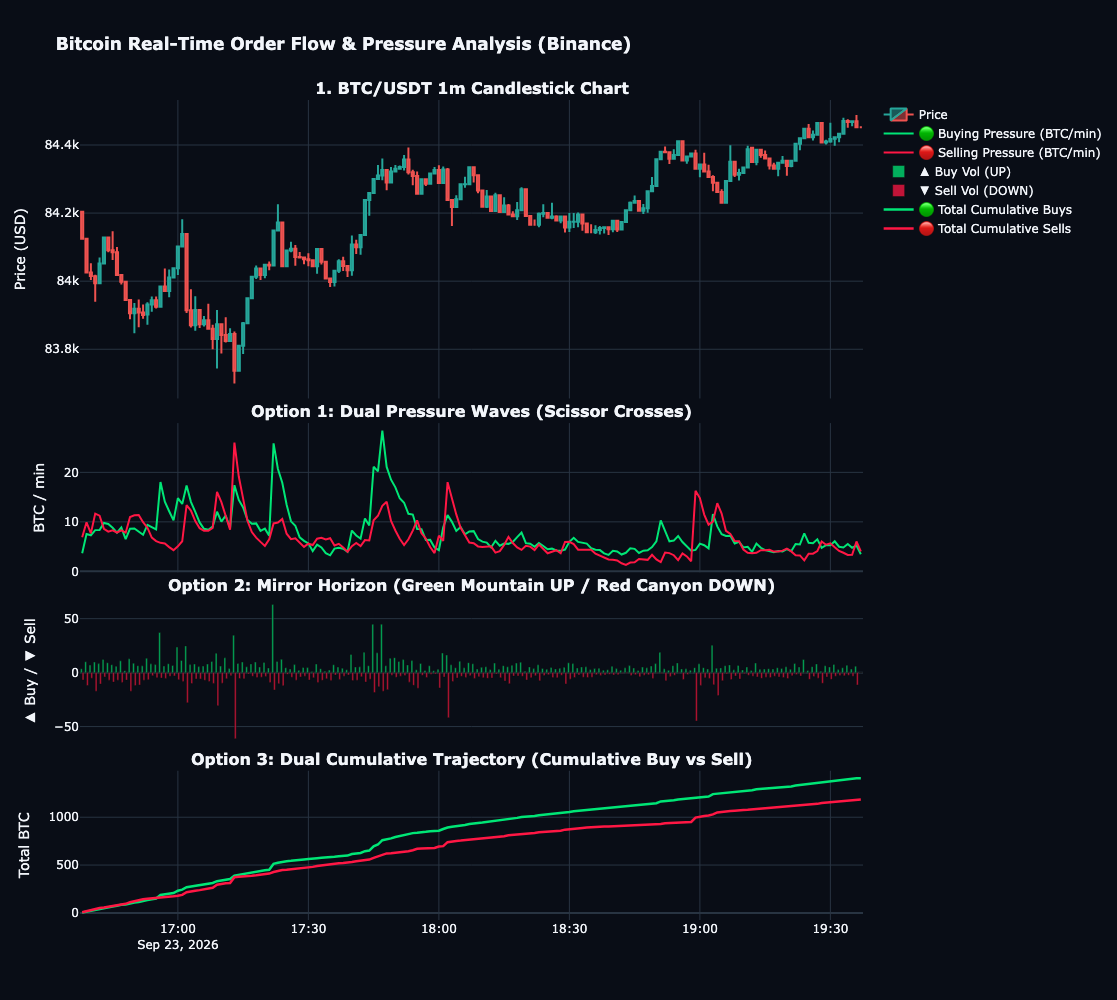

In [1]:
import requests
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Fetch real 1m BTCUSDT order-flow data from Binance public API
SYMBOL = 'BTCUSDT'
INTERVAL = '1m'
LIMIT = 180  # Last 3 hours of 1-minute data

url = f"https://api.binance.com/api/v3/klines?symbol={SYMBOL}&interval={INTERVAL}&limit={LIMIT}"
res = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}).json()

cols = [
    'open_time', 'open', 'high', 'low', 'close', 'volume',
    'close_time', 'quote_asset_volume', 'trades', 
    'taker_buy_vol', 'taker_buy_quote_vol', 'ignore'
]
df = pd.DataFrame(res, columns=cols)

# Convert numeric types
numeric_cols = ['open', 'high', 'low', 'close', 'volume', 'trades', 'taker_buy_vol']
df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric)
df['time'] = pd.to_datetime(df['open_time'], unit='ms')

# 2. Extract Separate Order-Flow Pressures (Zero Data Loss)
df['taker_sell_vol'] = df['volume'] - df['taker_buy_vol']

# Option 1: Smoothed Instantaneous Pressure (Dual Waves)
df['smooth_buy'] = df['taker_buy_vol'].ewm(span=5).mean()
df['smooth_sell'] = df['taker_sell_vol'].ewm(span=5).mean()

# Option 2: Mirror Horizon values (Sell is negative to project downward)
df['mirror_sell'] = -df['taker_sell_vol']

# Option 3: Cumulative Volume Trajectory (Dual CVD)
df['cum_buy'] = df['taker_buy_vol'].cumsum()
df['cum_sell'] = df['taker_sell_vol'].cumsum()

# 3. Create Synchronized 4-Row Interactive Dashboard
fig = make_subplots(
    rows=4, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.03,
    subplot_titles=(
        f"<b>1. BTC/USDT 1m Candlestick Chart</b>",
        f"<b>Option 1: Dual Pressure Waves (Scissor Crosses)</b>",
        f"<b>Option 2: Mirror Horizon (Green Mountain UP / Red Canyon DOWN)</b>",
        f"<b>Option 3: Dual Cumulative Trajectory (Cumulative Buy vs Sell)</b>"
    ),
    row_heights=[0.40, 0.20, 0.20, 0.20]
)

# ----------------- PANEL 1: CANDLESTICKS -----------------
fig.add_trace(
    go.Candlestick(
        x=df['time'], open=df['open'], high=df['high'], low=df['low'], close=df['close'],
        increasing_line_color='#26a69a', decreasing_line_color='#ef5350',
        name="Price"
    ),
    row=1, col=1
)

# ----------------- PANEL 2: OPTION 1 (DUAL PRESSURE WAVES) -----------------
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['smooth_buy'],
        mode='lines', line=dict(color='#00E676', width=2),
        name="🟢 Buying Pressure (BTC/min)"
    ),
    row=2, col=1
)
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['smooth_sell'],
        mode='lines', line=dict(color='#FF1744', width=2),
        name="🔴 Selling Pressure (BTC/min)"
    ),
    row=2, col=1
)

# ----------------- PANEL 3: OPTION 2 (MIRROR HORIZON) -----------------
fig.add_trace(
    go.Bar(
        x=df['time'], y=df['taker_buy_vol'],
        marker_color='rgba(0, 230, 118, 0.75)',
        name="▲ Buy Vol (UP)"
    ),
    row=3, col=1
)
fig.add_trace(
    go.Bar(
        x=df['time'], y=df['mirror_sell'],
        marker_color='rgba(255, 23, 68, 0.75)',
        name="▼ Sell Vol (DOWN)"
    ),
    row=3, col=1
)

# ----------------- PANEL 4: OPTION 3 (DUAL CUMULATIVE TRAJECTORY) -----------------
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['cum_buy'],
        mode='lines', line=dict(color='#00E676', width=2.5),
        name="🟢 Total Cumulative Buys"
    ),
    row=4, col=1
)
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['cum_sell'],
        mode='lines', line=dict(color='#FF1744', width=2.5),
        name="🔴 Total Cumulative Sells"
    ),
    row=4, col=1
)

# ----------------- DASHBOARD STYLING -----------------
fig.update_layout(
    title="<b>Bitcoin Real-Time Order Flow & Pressure Analysis (Binance)</b>",
    template="plotly_dark",
    height=1000,
    showlegend=True,
    xaxis_rangeslider_visible=False,
    hovermode='x unified',
    paper_bgcolor='#090d16',
    plot_bgcolor='#090d16'
)

fig.update_yaxes(title_text="Price (USD)", row=1, col=1)
fig.update_yaxes(title_text="BTC / min", row=2, col=1)
fig.update_yaxes(title_text="▲ Buy / ▼ Sell", row=3, col=1)
fig.update_yaxes(title_text="Total BTC", row=4, col=1)

fig.show()

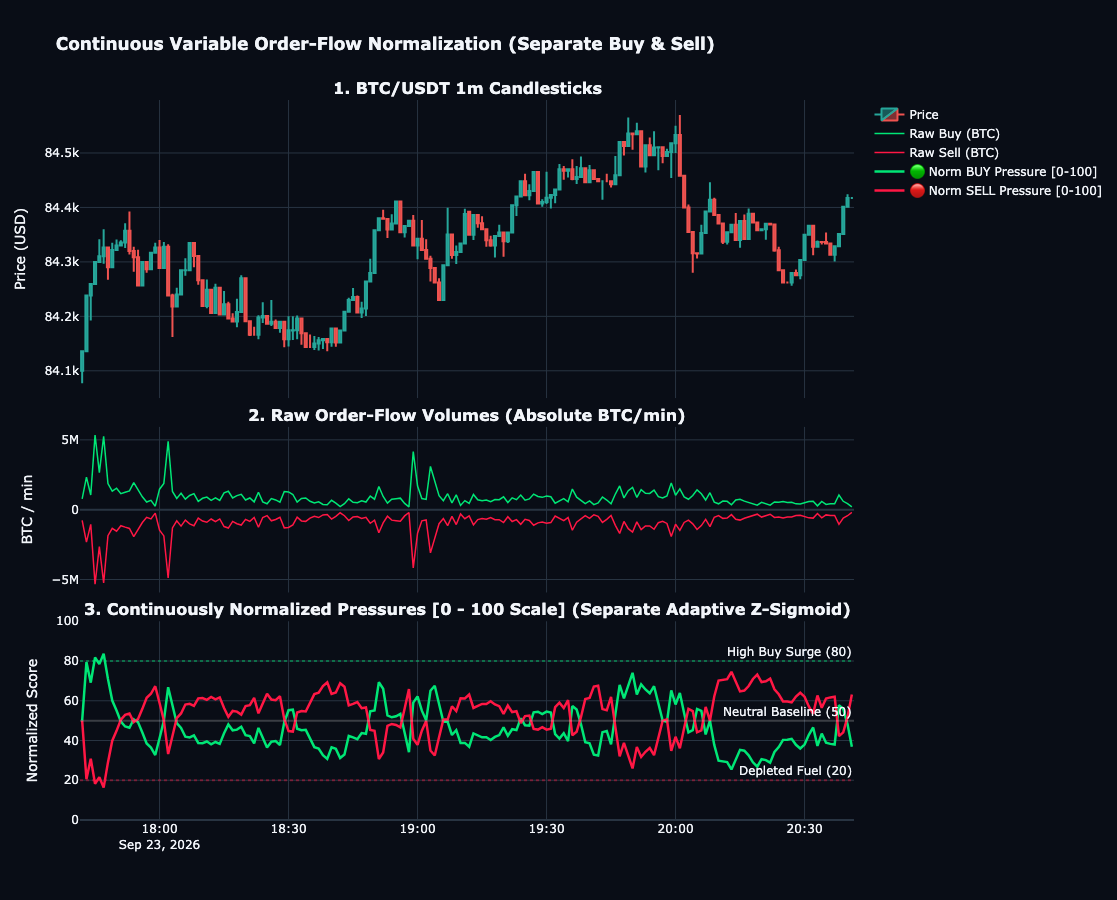

In [2]:
import requests
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Fetch real 1m BTCUSDT order-flow data from Binance
SYMBOL = 'BTCUSDT'
INTERVAL = '1m'
LIMIT = 180  # 3 hours of 1-minute data

url = f"https://api.binance.com/api/v3/klines?symbol={SYMBOL}&interval={INTERVAL}&limit={LIMIT}"
res = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}).json()

cols = ['open_time', 'open', 'high', 'low', 'close', 'volume', '_', '_', 'trades', 'taker_buy_vol', '_', '_']
df = pd.DataFrame(res).iloc[:, :10]
df.columns = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'trades', 'taker_buy_vol', 'extra1', 'extra2']
df = df[['open_time', 'open', 'high', 'low', 'close', 'volume', 'trades', 'taker_buy_vol']].apply(pd.to_numeric)
df['time'] = pd.to_datetime(df['open_time'], unit='ms')

# Extract raw pressures
df['taker_sell_vol'] = df['volume'] - df['taker_buy_vol']

# 2. Continuous Variable Streaming Normalization (Separately for Buy & Sell)
def continuous_streaming_normalize(series, alpha=0.08):
    """
    Causal running Z-Score mapped to continuous [0, 100]% via Sigmoid.
    alpha=0.08 adapts to roughly the last ~20-25 bars of volatility.
    """
    n = len(series)
    norm = np.zeros(n)
    mean = series.iloc[0]
    var = 1.0

    for i in range(n):
        x = series.iloc[i]
        mean = alpha * x + (1 - alpha) * mean
        diff = x - mean
        var = alpha * (diff ** 2) + (1 - alpha) * var
        std = np.sqrt(max(var, 1e-6))
        z = (x - mean) / std
        # Sigmoid: z=0 -> 50, z=+2 -> ~88, z=+3 -> ~95, z=-2 -> ~12
        norm[i] = 100.0 / (1.0 + np.exp(-z))

    return norm

# Separately normalize buying and selling pressure
df['norm_buy'] = continuous_streaming_normalize(df['taker_buy_vol'])
df['norm_sell'] = continuous_streaming_normalize(df['taker_sell_vol'])

# Also compute a smooth continuous line (EMA) of each normalized pressure
df['norm_buy_smooth'] = pd.Series(df['norm_buy']).ewm(span=4).mean()
df['norm_sell_smooth'] = pd.Series(df['norm_sell']).ewm(span=4).mean()

# 3. Create Synchronized Multi-Panel Plotly Figure
fig = make_subplots(
    rows=3, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.04,
    subplot_titles=(
        f"<b>1. BTC/USDT 1m Candlesticks</b>",
        f"<b>2. Raw Order-Flow Volumes (Absolute BTC/min)</b>",
        f"<b>3. Continuously Normalized Pressures [0 - 100 Scale] (Separate Adaptive Z-Sigmoid)</b>"
    ),
    row_heights=[0.45, 0.25, 0.30]
)

# Panel 1: Price
fig.add_trace(
    go.Candlestick(
        x=df['time'], open=df['open'], high=df['high'], low=df['low'], close=df['close'],
        increasing_line_color='#26a69a', decreasing_line_color='#ef5350',
        name="Price"
    ),
    row=1, col=1
)

# Panel 2: Raw BTC Volumes
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['taker_buy_vol'],
        mode='lines', line=dict(color='#00E676', width=1.5),
        name="Raw Buy (BTC)"
    ),
    row=2, col=1
)
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['taker_sell_vol'],
        mode='lines', line=dict(color='#FF1744', width=1.5),
        name="Raw Sell (BTC)"
    ),
    row=2, col=1
)

# Panel 3: Continuously Normalized Separate Pressures
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['norm_buy_smooth'],
        mode='lines', line=dict(color='#00E676', width=2.5),
        name="🟢 Norm BUY Pressure [0-100]"
    ),
    row=3, col=1
)
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['norm_sell_smooth'],
        mode='lines', line=dict(color='#FF1744', width=2.5),
        name="🔴 Norm SELL Pressure [0-100]"
    ),
    row=3, col=1
)

# Reference benchmark lines for Normalized panel
fig.add_hline(y=80, line_dash="dot", line_color="rgba(0, 230, 118, 0.4)", row=3, col=1, annotation_text="High Buy Surge (80)")
fig.add_hline(y=50, line_dash="solid", line_color="rgba(255, 255, 255, 0.2)", row=3, col=1, annotation_text="Neutral Baseline (50)")
fig.add_hline(y=20, line_dash="dot", line_color="rgba(255, 23, 68, 0.4)", row=3, col=1, annotation_text="Depleted Fuel (20)")

fig.update_layout(
    title="<b>Continuous Variable Order-Flow Normalization (Separate Buy & Sell)</b>",
    template="plotly_dark",
    height=900,
    showlegend=True,
    xaxis_rangeslider_visible=False,
    hovermode='x unified',
    paper_bgcolor='#090d16',
    plot_bgcolor='#090d16'
)

fig.update_yaxes(title_text="Price (USD)", row=1, col=1)
fig.update_yaxes(title_text="BTC / min", row=2, col=1)
fig.update_yaxes(title_text="Normalized Score", range=[0, 100], row=3, col=1)

fig.show()

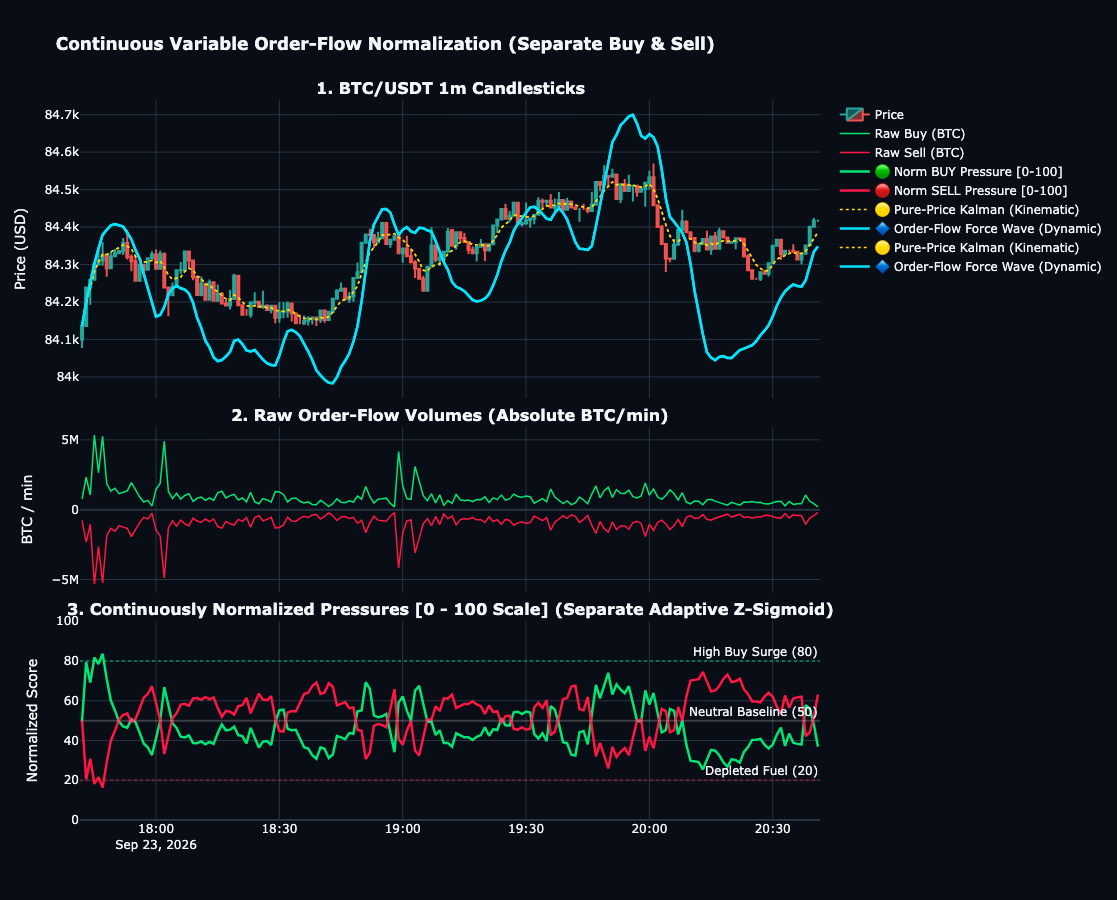

In [4]:
# 4. Compute Force-Augmented Order-Flow Kalman Wave
def compute_force_kalman(prices, norm_buys, norm_sells, atrs, kappa=0.8, gamma=0.15):
    n = len(prices)
    dt = 1.0
    
    # State: [price, velocity]
    x = np.array([prices.iloc[0], 0.0])
    P = np.eye(2) * 5.0
    Q = np.array([[0.01, 0.0], [0.0, 0.05]])
    R = 8.0  # Measurement variance
    
    F = np.array([[1.0, dt], [0.0, 1.0 - gamma * dt]])
    B = np.array([0.5 * dt**2, dt])
    H = np.array([[1.0, 0.0]])
    
    force_wave_price = np.zeros(n)
    pure_wave_price = np.zeros(n)
    
    # Run Pure-Price Kalman (no force: u = 0)
    x_pure = np.array([prices.iloc[0], 0.0])
    P_pure = np.eye(2) * 5.0
    for i in range(n):
        # Pure
        x_pred_p = F @ x_pure
        P_pred_p = F @ P_pure @ F.T + Q
        y_p = prices.iloc[i] - (H @ x_pred_p)[0]
        K_p = (P_pred_p @ H.T) / ((H @ P_pred_p @ H.T)[0,0] + R)
        x_pure = x_pred_p + K_p.flatten() * y_p
        P_pure = (np.eye(2) - K_p @ H) @ P_pred_p
        pure_wave_price[i] = x_pure[0]
        
        # Force-Augmented: u = (Norm_Buy - Norm_Sell) / 50
        net_force = (norm_buys[i] - norm_sells[i]) / 50.0
        u_scaled = net_force * kappa * atrs.iloc[i]
        
        x_pred_f = F @ x + B * u_scaled
        P_pred_f = F @ P @ F.T + Q
        y_f = prices.iloc[i] - (H @ x_pred_f)[0]
        K_f = (P_pred_f @ H.T) / ((H @ P_pred_f @ H.T)[0,0] + R)
        x = x_pred_f + K_f.flatten() * y_f
        P = (np.eye(2) - K_f @ H) @ P_pred_f
        force_wave_price[i] = x[0]
        
    return pure_wave_price, force_wave_price

# Calculate ATR for scaling
df['tr'] = np.maximum(df['high'] - df['low'], 
           np.maximum(abs(df['high'] - df['close'].shift(1)), 
                      abs(df['low'] - df['close'].shift(1)))).fillna(10.0)
df['atr'] = df['tr'].rolling(14).mean().fillna(15.0)

df['pure_wave'], df['force_wave'] = compute_force_kalman(
    df['close'], df['norm_buy'], df['norm_sell'], df['atr']
)

# Plot both waves directly on Panel 1 (Candlesticks)
fig.add_trace(
    go.Scatter(x=df['time'], y=df['pure_wave'], mode='lines',
               line=dict(color='#FFD700', width=1.5, dash='dot'),
               name="🟡 Pure-Price Kalman (Kinematic)"),
    row=1, col=1
)
fig.add_trace(
    go.Scatter(x=df['time'], y=df['force_wave'], mode='lines',
               line=dict(color='#00E5FF', width=2.5),
               name="🔷 Order-Flow Force Wave (Dynamic)"),
    row=1, col=1
)
fig.show()

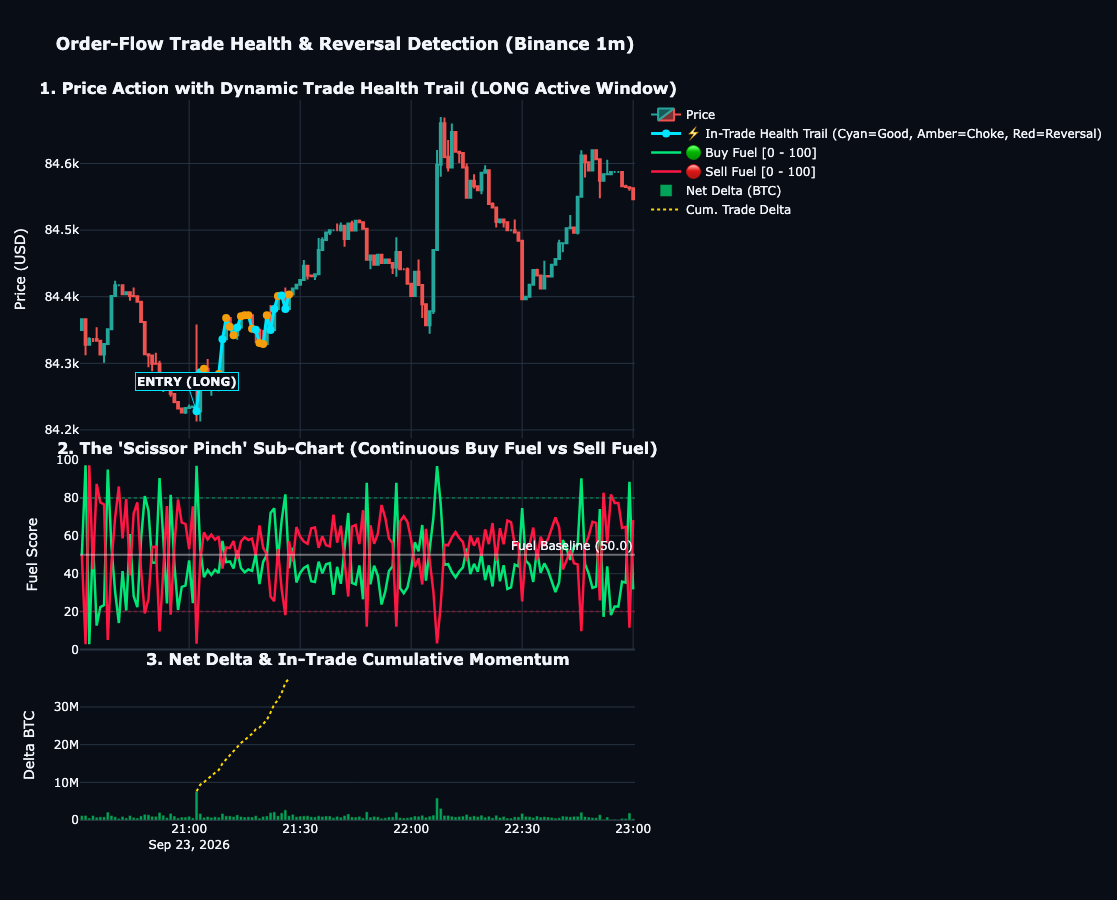

In [5]:
import requests
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# 1. Fetch real 1m BTCUSDT order-flow data from Binance public API
SYMBOL = 'BTCUSDT'
INTERVAL = '1m'
LIMIT = 150  # Last 2.5 hours of 1-minute data

url = f"https://api.binance.com/api/v3/klines?symbol={SYMBOL}&interval={INTERVAL}&limit={LIMIT}"
res = requests.get(url, headers={'User-Agent': 'Mozilla/5.0'}).json()

cols = ['open_time', 'open', 'high', 'low', 'close', 'volume', '_', '_', 'trades', 'taker_buy_vol', '_', '_']
df = pd.DataFrame(res).iloc[:, :10]
df.columns = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'trades', 'taker_buy_vol', 'extra1', 'extra2']
df = df[['open_time', 'open', 'high', 'low', 'close', 'volume', 'trades', 'taker_buy_vol']].apply(pd.to_numeric)
df['time'] = pd.to_datetime(df['open_time'], unit='ms')

# Extract buying and selling order-flow
df['taker_sell_vol'] = df['volume'] - df['taker_buy_vol']
df['net_delta'] = df['taker_buy_vol'] - df['taker_sell_vol']

# 2. Causal Continuous Normalization (Adaptive Z-Sigmoid [0 - 100])
def continuous_normalize(series, alpha=0.08):
    n = len(series)
    norm = np.zeros(n)
    mean, var = series.iloc[0], 1.0
    for i in range(n):
        x = series.iloc[i]
        mean = alpha * x + (1 - alpha) * mean
        diff = x - mean
        var = alpha * (diff ** 2) + (1 - alpha) * var
        std = np.sqrt(max(var, 1e-6))
        z = (x - mean) / std
        norm[i] = 100.0 / (1.0 + np.exp(-z))
    return norm

df['norm_buy'] = continuous_normalize(df['taker_buy_vol'])
df['norm_sell'] = continuous_normalize(df['taker_sell_vol'])

# 3. Simulate an Active Trade Life-Cycle for Dynamic Health Trail
# (Detects the largest recent momentum impulse to demonstrate the trail)
abs_delta = df['net_delta'].abs()
peak_idx = int(abs_delta.iloc[20:-20].idxmax())
trade_dir = 'LONG' if df['net_delta'].iloc[peak_idx] > 0 else 'SHORT'
entry_idx = peak_idx
exit_idx = min(len(df) - 1, entry_idx + 25)

# Calculate Trade Health State on each candle:
# • 🟢 Healthy (Fuel >= 50 and dominant)
# • 🟡 Choked (Fuel < 50)
# • 🔴 Reversed (Delta flipped against position)
health_colors = []
for i in range(entry_idx, exit_idx + 1):
    fuel = df['norm_buy'].iloc[i] if trade_dir == 'LONG' else df['norm_sell'].iloc[i]
    delta = df['net_delta'].iloc[i]
    opp_fuel = df['norm_sell'].iloc[i] if trade_dir == 'LONG' else df['norm_buy'].iloc[i]
    
    if (trade_dir == 'LONG' and delta < 0) or (trade_dir == 'SHORT' and delta > 0):
        health_colors.append('#FF1744')  # 🔴 Red: Opponent took over
    elif fuel < 50.0:
        health_colors.append('#F59E0B')  # 🟡 Amber: Fuel choked
    else:
        health_colors.append('#00E5FF')  # 🟢 Cyan: Healthy momentum

# 4. Create ONLY the 3 Synchronized Visual Charts
fig = make_subplots(
    rows=3, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.03,
    subplot_titles=(
        f"<b>1. Price Action with Dynamic Trade Health Trail ({trade_dir} Active Window)</b>",
        f"<b>2. The 'Scissor Pinch' Sub-Chart (Continuous Buy Fuel vs Sell Fuel)</b>",
        f"<b>3. Net Delta & In-Trade Cumulative Momentum</b>"
    ),
    row_heights=[0.50, 0.28, 0.22]
)

# ----------------- CHART 1: PRICE + DYNAMIC HEALTH TRAIL -----------------
fig.add_trace(
    go.Candlestick(
        x=df['time'], open=df['open'], high=df['high'], low=df['low'], close=df['close'],
        increasing_line_color='#26a69a', decreasing_line_color='#ef5350',
        name="Price"
    ),
    row=1, col=1
)

# Dynamic Trade Health Trail overlay
fig.add_trace(
    go.Scatter(
        x=df['time'].iloc[entry_idx:exit_idx + 1],
        y=df['close'].iloc[entry_idx:exit_idx + 1],
        mode='lines+markers',
        line=dict(width=3, color='#00E5FF'),
        marker=dict(size=8, color=health_colors),
        name="⚡ In-Trade Health Trail (Cyan=Good, Amber=Choke, Red=Reversal)"
    ),
    row=1, col=1
)

# Entry Marker
fig.add_annotation(
    x=df['time'].iloc[entry_idx], y=df['close'].iloc[entry_idx],
    text=f"<b>ENTRY ({trade_dir})</b>", showarrow=True, arrowhead=2,
    arrowcolor="#00E5FF", bgcolor="#090d16", bordercolor="#00E5FF",
    row=1, col=1
)

# ----------------- CHART 2: THE SCISSOR PINCH (0 - 100) -----------------
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['norm_buy'],
        mode='lines', line=dict(color='#00E676', width=2.5),
        name="🟢 Buy Fuel [0 - 100]"
    ),
    row=2, col=1
)
fig.add_trace(
    go.Scatter(
        x=df['time'], y=df['norm_sell'],
        mode='lines', line=dict(color='#FF1744', width=2.5),
        name="🔴 Sell Fuel [0 - 100]"
    ),
    row=2, col=1
)

# Statistical Mean Baseline Reference (50)
fig.add_hline(y=50, line_dash="solid", line_color="rgba(255, 255, 255, 0.4)", row=2, col=1, annotation_text="Fuel Baseline (50.0)")
fig.add_hline(y=80, line_dash="dot", line_color="rgba(0, 230, 118, 0.3)", row=2, col=1)
fig.add_hline(y=20, line_dash="dot", line_color="rgba(255, 23, 68, 0.3)", row=2, col=1)

# ----------------- CHART 3: NET DELTA & CUMULATIVE FLOW -----------------
delta_colors = np.where(df['net_delta'] >= 0, 'rgba(0, 230, 118, 0.7)', 'rgba(255, 23, 68, 0.7)')
fig.add_trace(
    go.Bar(
        x=df['time'], y=df['net_delta'],
        marker_color=delta_colors,
        name="Net Delta (BTC)"
    ),
    row=3, col=1
)

# Cumulative in-trade flow line
cum_trade_delta = df['net_delta'].iloc[entry_idx:exit_idx + 1].cumsum()
fig.add_trace(
    go.Scatter(
        x=df['time'].iloc[entry_idx:exit_idx + 1],
        y=cum_trade_delta,
        mode='lines', line=dict(color='#FFD700', width=2, dash='dot'),
        name="Cum. Trade Delta"
    ),
    row=3, col=1
)

# ----------------- DASHBOARD STYLING -----------------
fig.update_layout(
    title="<b>Order-Flow Trade Health & Reversal Detection (Binance 1m)</b>",
    template="plotly_dark",
    height=900,
    showlegend=True,
    xaxis_rangeslider_visible=False,
    hovermode='x unified',
    paper_bgcolor='#090d16',
    plot_bgcolor='#090d16'
)

fig.update_yaxes(title_text="Price (USD)", row=1, col=1)
fig.update_yaxes(title_text="Fuel Score", range=[0, 100], row=2, col=1)
fig.update_yaxes(title_text="Delta BTC", row=3, col=1)

fig.show()

Fetching latest live data from Binance...
Loaded 300 candles from 2026-09-23 19:31:00 to 2026-09-24 00:30:00


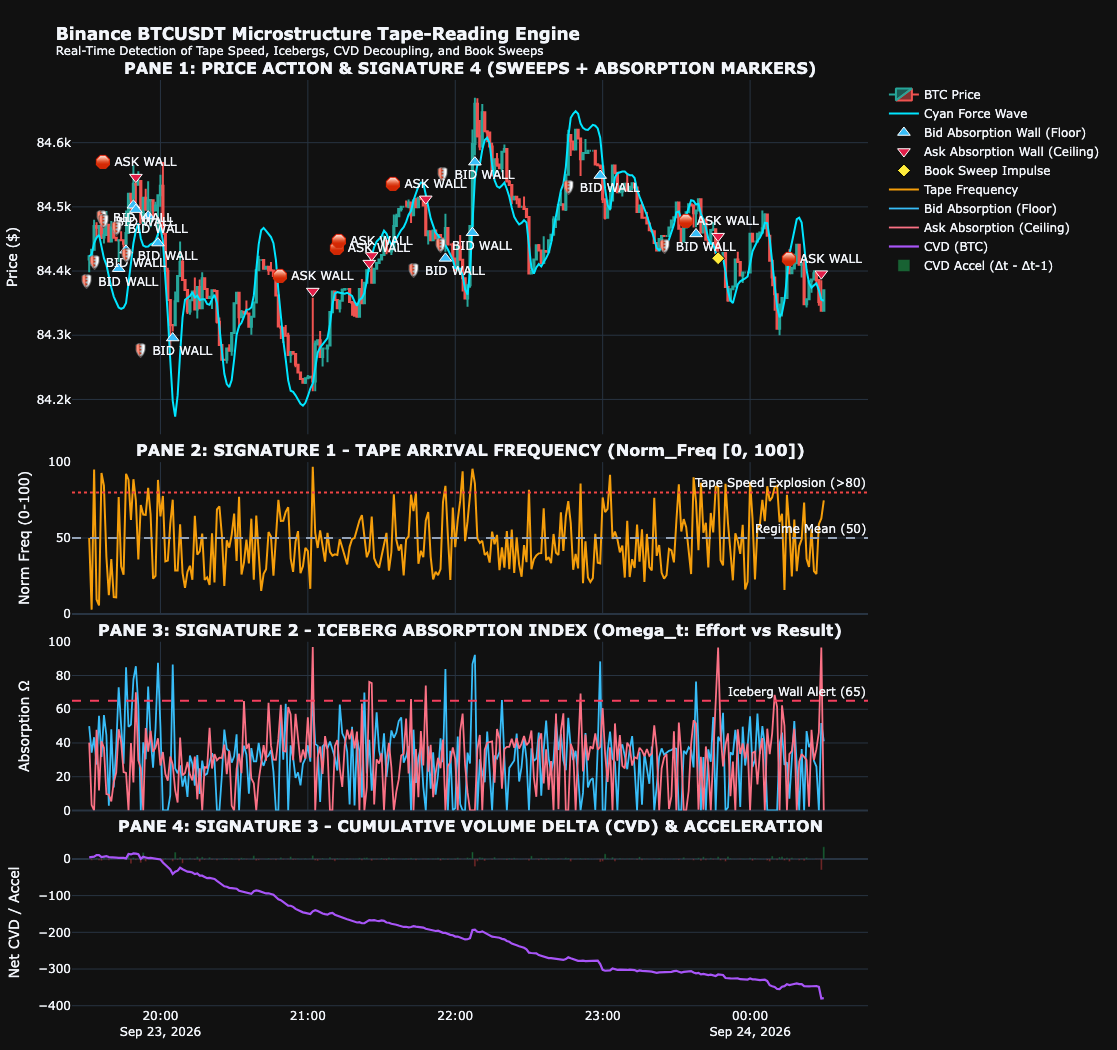

In [6]:
# ==============================================================================
# MICROSTRUCTURE TAPE-READING DASHBOARD (GOOGLE COLAB)
# Visualizing the 4 Tape-Reading Signatures:
#   1. Normalized Tape Arrival Frequency (Norm_Freq ∈ [0, 100])
#   2. Whale Iceberg Absorption Index (Omega_t: Effort vs. Result)
#   3. Cumulative Volume Delta (CVD) & CVD Acceleration (a_CVD)
#   4. Multi-Level Book Sweep Markers (Phi_t on Candlesticks)
# ==============================================================================

import json
import urllib.request
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ------------------------------------------------------------------------------
# 1. Fetch Real Binance Microstructure Klines
# ------------------------------------------------------------------------------
def fetch_binance_microstructure(symbol="BTCUSDT", interval="1m", limit=300):
    url = f"https://api.binance.com/api/v3/klines?symbol={symbol}&interval={interval}&limit={limit}"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp:
        raw = json.loads(resp.read().decode())
    
    df = pd.DataFrame(raw, columns=[
        "open_time", "open", "high", "low", "close", "volume",
        "close_time", "quote_volume", "trades", "taker_buy_vol",
        "taker_buy_quote_vol", "ignore"
    ])
    
    for col in ["open", "high", "low", "close", "volume", "trades", "taker_buy_vol"]:
        df[col] = df[col].astype(float)
        
    df["datetime"] = pd.to_datetime(df["open_time"], unit="ms")
    df["taker_sell_vol"] = np.maximum(0.0, df["volume"] - df["taker_buy_vol"])
    df["delta"] = df["taker_buy_vol"] - df["taker_sell_vol"]
    return df

print("Fetching latest live data from Binance...")
df = fetch_binance_microstructure(symbol="BTCUSDT", interval="1m", limit=300)
n = len(df)
print(f"Loaded {n} candles from {df['datetime'].iloc[0]} to {df['datetime'].iloc[-1]}")

# ------------------------------------------------------------------------------
# 2. Causal Continuous Streaming Normalization (Zero Lookahead)
# ------------------------------------------------------------------------------
def causal_welford_norm(series, alpha=0.08):
    norm = np.zeros(len(series))
    mean = series[0]
    var = 1.0
    for i in range(len(series)):
        x = series[i]
        mean = alpha * x + (1.0 - alpha) * mean
        diff = x - mean
        var = alpha * (diff ** 2) + (1.0 - alpha) * var
        std = np.sqrt(max(var, 1e-6))
        z = (x - mean) / std
        norm[i] = 100.0 / (1.0 + np.exp(-z))  # Sigmoid bounded [0, 100]
    return norm

# Compute Continuous Streaming Pressures
df["norm_buy"] = causal_welford_norm(df["taker_buy_vol"].values, alpha=0.08)
df["norm_sell"] = causal_welford_norm(df["taker_sell_vol"].values, alpha=0.08)

# SIGNATURE 1: Normalized Tape Arrival Frequency (Trade Rate of Change)
df["norm_freq"] = causal_welford_norm(df["trades"].values, alpha=0.08)

# ------------------------------------------------------------------------------
# 3. Dynamic ATR & Physics-Informed Kalman Force Wave
# ------------------------------------------------------------------------------
highs = df["high"].values
lows = df["low"].values
closes = df["close"].values

tr = np.maximum(highs - lows, np.maximum(np.abs(highs - np.roll(closes, 1)), np.abs(lows - np.roll(closes, 1))))
tr[0] = highs[0] - lows[0]
atr = np.zeros(n)
cur_atr = tr[0]
for i in range(n):
    cur_atr = (1.0 / 14.0) * tr[i] + (13.0 / 14.0) * cur_atr
    atr[i] = cur_atr
df["atr"] = atr

# Physics Kalman Wave
dt, gamma, kappa = 1.0, 0.15, 0.8
Q_p, Q_v, R = 0.01, 0.05, 8.0
p, v = closes[0], 0.0
P00, P01, P10, P11 = 5.0, 0.0, 0.0, 5.0
cyan_price = np.zeros(n)
cyan_vel = np.zeros(n)

for i in range(n):
    u = ((df["norm_buy"].iloc[i] - df["norm_sell"].iloc[i]) / 50.0) * kappa * atr[i]
    p_pred = p + v * dt + 0.5 * dt**2 * u
    v_pred = (1.0 - gamma * dt) * v + dt * u
    
    F11 = 1.0 - gamma * dt
    NP00 = P00 + dt * (P10 + P01) + dt**2 * P11 + Q_p
    NP01 = P01 + dt * P11 * F11
    NP10 = P10 + dt * P11 * F11
    NP11 = F11 * P11 * F11 + Q_v
    
    y = closes[i] - p_pred
    S = NP00 + R
    K0 = NP00 / S
    K1 = NP10 / S
    
    p = p_pred + K0 * y
    v = v_pred + K1 * y
    
    P00 = (1.0 - K0) * NP00
    P01 = (1.0 - K0) * NP01
    P10 = -K1 * NP00 + NP10
    P11 = -K1 * NP01 + NP11
    cyan_price[i] = p
    cyan_vel[i] = v

df["cyan_price"] = cyan_price
df["cyan_vel"] = cyan_vel

# ------------------------------------------------------------------------------
# 4. SIGNATURE 2: Iceberg Absorption Index (Effort Without Result)
# ------------------------------------------------------------------------------
opens = df["open"].values
omega_bid = np.zeros(n)
omega_ask = np.zeros(n)

for i in range(n):
    # Bid Absorption: Heavy selling effort (Norm_Sell high), but price failed to slide down
    disp_down = max(0.0, opens[i] - closes[i])
    omega_bid[i] = df["norm_sell"].iloc[i] * max(0.0, 1.0 - (disp_down / atr[i]))
    
    # Ask Absorption: Heavy buying effort (Norm_Buy high), but price failed to push up
    disp_up = max(0.0, closes[i] - opens[i])
    omega_ask[i] = df["norm_buy"].iloc[i] * max(0.0, 1.0 - (disp_up / atr[i]))

df["omega_bid"] = omega_bid
df["omega_ask"] = omega_ask

# ------------------------------------------------------------------------------
# 5. SIGNATURE 3: CVD & CVD Acceleration (a_CVD)
# ------------------------------------------------------------------------------
df["cvd"] = df["delta"].cumsum()
df["cvd_accel"] = df["delta"].diff().fillna(0.0)

# ------------------------------------------------------------------------------
# 6. SIGNATURE 4: Participation Density & Book Sweeps
# ------------------------------------------------------------------------------
df["btc_per_trade"] = df["volume"] / np.maximum(df["trades"], 1.0)
df["norm_density"] = causal_welford_norm(df["btc_per_trade"].values, alpha=0.08)
# A sweep combines institutional size per trade with high tape arrival speed
df["sweep_intensity"] = (df["norm_density"] * df["norm_freq"]) / 100.0

# Extract Markers for Candlestick Chart
bid_icebergs = df[df["omega_bid"] >= 70.0]
ask_icebergs = df[df["omega_ask"] >= 70.0]
sweeps = df[df["sweep_intensity"] >= 65.0]

# ------------------------------------------------------------------------------
# 7. Render Interactive Plotly 4-Pane Figure
# ------------------------------------------------------------------------------
fig = make_subplots(
    rows=4, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.03,
    subplot_titles=(
        "<b>PANE 1: PRICE ACTION & SIGNATURE 4 (SWEEPS + ABSORPTION MARKERS)</b>",
        "<b>PANE 2: SIGNATURE 1 - TAPE ARRIVAL FREQUENCY (Norm_Freq [0, 100])</b>",
        "<b>PANE 3: SIGNATURE 2 - ICEBERG ABSORPTION INDEX (Omega_t: Effort vs Result)</b>",
        "<b>PANE 4: SIGNATURE 3 - CUMULATIVE VOLUME DELTA (CVD) & ACCELERATION</b>"
    ),
    row_heights=[0.42, 0.18, 0.20, 0.20]
)

# --- PANE 1: Candlesticks & Cyan Force Wave ---
fig.add_trace(go.Candlestick(
    x=df["datetime"], open=df["open"], high=df["high"], low=df["low"], close=df["close"],
    name="BTC Price", increasing_line_color="#26a69a", decreasing_line_color="#ef5350"
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["cyan_price"],
    mode="lines", name="Cyan Force Wave", line=dict(color="#00e5ff", width=2)
), row=1, col=1)

# Markers: Bid Iceberg Wall (Whale Support Floor)
if not bid_icebergs.empty:
    fig.add_trace(go.Scatter(
        x=bid_icebergs["datetime"], y=bid_icebergs["low"] - (df["atr"].mean() * 0.4),
        mode="markers+text", name="Bid Absorption Wall (Floor)",
        text="🛡️ BID WALL", textposition="bottom center",
        marker=dict(symbol="triangle-up", color="#38bdf8", size=11, line=dict(width=1, color="#ffffff"))
    ), row=1, col=1)

# Markers: Ask Iceberg Wall (Whale Resistance Ceiling)
if not ask_icebergs.empty:
    fig.add_trace(go.Scatter(
        x=ask_icebergs["datetime"], y=ask_icebergs["high"] + (df["atr"].mean() * 0.4),
        mode="markers+text", name="Ask Absorption Wall (Ceiling)",
        text="🛑 ASK WALL", textposition="top center",
        marker=dict(symbol="triangle-down", color="#e11d48", size=11, line=dict(width=1, color="#ffffff"))
    ), row=1, col=1)

# Markers: Multi-Level Book Sweep
if not sweeps.empty:
    fig.add_trace(go.Scatter(
        x=sweeps["datetime"], y=sweeps["close"],
        mode="markers", name="Book Sweep Impulse",
        marker=dict(symbol="diamond", color="#ffeb3b", size=10, line=dict(width=1, color="#000000"))
    ), row=1, col=1)

# --- PANE 2: Signature 1 (Tape Frequency) ---
fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["norm_freq"],
    mode="lines", name="Tape Frequency", line=dict(color="#f59e0b", width=2)
), row=2, col=1)
fig.add_hline(y=50.0, line_dash="dash", line_color="#94a3b8", row=2, col=1, annotation_text="Regime Mean (50)")
fig.add_hline(y=80.0, line_dash="dot", line_color="#ef4444", row=2, col=1, annotation_text="Tape Speed Explosion (>80)")

# --- PANE 3: Signature 2 (Absorption Index) ---
fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["omega_bid"],
    mode="lines", name="Bid Absorption (Floor)", line=dict(color="#38bdf8", width=1.8)
), row=3, col=1)
fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["omega_ask"],
    mode="lines", name="Ask Absorption (Ceiling)", line=dict(color="#fb7185", width=1.8)
), row=3, col=1)
fig.add_hline(y=65.0, line_dash="dash", line_color="#f43f5e", row=3, col=1, annotation_text="Iceberg Wall Alert (65)")

# --- PANE 4: Signature 3 (CVD & CVD Acceleration) ---
fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["cvd"],
    mode="lines", name="CVD (BTC)", line=dict(color="#a855f7", width=2.2)
), row=4, col=1)

# Acceleration Bars
colors = ["#22c55e" if a >= 0 else "#ef4444" for a in df["cvd_accel"]]
fig.add_trace(go.Bar(
    x=df["datetime"], y=df["cvd_accel"],
    name="CVD Accel (Δt - Δt-1)", marker_color=colors, opacity=0.45
), row=4, col=1)

# Layout Formatting
fig.update_layout(
    title="<b>Binance BTCUSDT Microstructure Tape-Reading Engine</b><br><sup>Real-Time Detection of Tape Speed, Icebergs, CVD Decoupling, and Book Sweeps</sup>",
    template="plotly_dark",
    height=1050,
    showlegend=True,
    xaxis_rangeslider_visible=False,
    hovermode="x unified",
    margin=dict(l=40, r=40, t=80, b=40)
)

fig.update_yaxes(title_text="Price ($)", row=1, col=1)
fig.update_yaxes(title_text="Norm Freq (0-100)", range=[0, 100], row=2, col=1)
fig.update_yaxes(title_text="Absorption Ω", range=[0, 100], row=3, col=1)
fig.update_yaxes(title_text="Net CVD / Accel", row=4, col=1)

fig.show()

Fetching latest live data from Binance...
Loaded 300 candles from 2026-09-23 19:41:00 to 2026-09-24 00:40:00


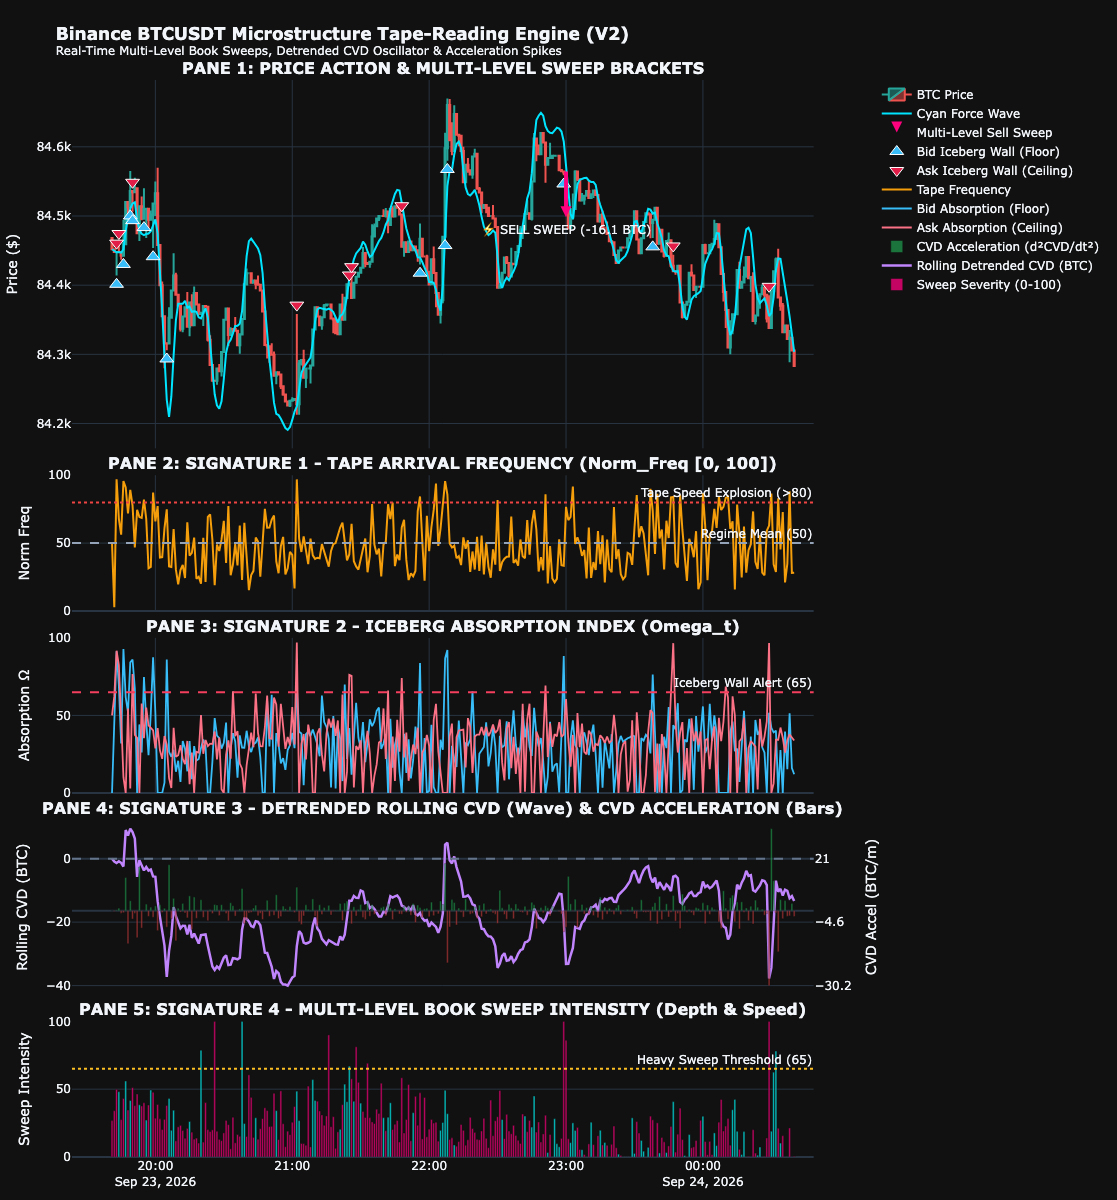

In [7]:
# ==============================================================================
# UPGRADED MICROSTRUCTURE TAPE-READING DASHBOARD (GOOGLE COLAB)
# Features:
#   1. Candlestick Price + Multi-Level Book Sweep Brackets (Cyan/Magenta Lasers)
#   2. Signature 1: Normalized Tape Arrival Frequency (Norm_Freq [0, 100])
#   3. Signature 2: Whale Iceberg Absorption Index (Omega_t: Effort vs. Result)
#   4. Signature 3: Detrended Rolling CVD (Oscillator) + BOLD CVD Acceleration Bars (Dual Y-Axis)
#   5. Signature 4: Multi-Level Book Sweep Severity & Depth Index
# ==============================================================================

import json
import urllib.request
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ------------------------------------------------------------------------------
# 1. Fetch Binance 1-Minute Microstructure Klines
# ------------------------------------------------------------------------------
def fetch_binance_data(symbol="BTCUSDT", interval="1m", limit=300):
    url = f"https://api.binance.com/api/v3/klines?symbol={symbol}&interval={interval}&limit={limit}"
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as resp:
        raw = json.loads(resp.read().decode())
    
    df = pd.DataFrame(raw, columns=[
        "open_time", "open", "high", "low", "close", "volume",
        "close_time", "quote_volume", "trades", "taker_buy_vol",
        "taker_buy_quote_vol", "ignore"
    ])
    
    for col in ["open", "high", "low", "close", "volume", "trades", "taker_buy_vol"]:
        df[col] = df[col].astype(float)
        
    df["datetime"] = pd.to_datetime(df["open_time"], unit="ms")
    df["taker_sell_vol"] = np.maximum(0.0, df["volume"] - df["taker_buy_vol"])
    df["delta"] = df["taker_buy_vol"] - df["taker_sell_vol"]
    return df

print("Fetching latest live data from Binance...")
df = fetch_binance_data(symbol="BTCUSDT", interval="1m", limit=300)
n = len(df)
print(f"Loaded {n} candles from {df['datetime'].iloc[0]} to {df['datetime'].iloc[-1]}")

# ------------------------------------------------------------------------------
# 2. Causal Continuous Normalization
# ------------------------------------------------------------------------------
def causal_welford_norm(series, alpha=0.08):
    norm = np.zeros(len(series))
    mean = series[0]
    var = 1.0
    for i in range(len(series)):
        x = series[i]
        mean = alpha * x + (1.0 - alpha) * mean
        diff = x - mean
        var = alpha * (diff ** 2) + (1.0 - alpha) * var
        std = np.sqrt(max(var, 1e-6))
        z = (x - mean) / std
        norm[i] = 100.0 / (1.0 + np.exp(-z))
    return norm

df["norm_buy"] = causal_welford_norm(df["taker_buy_vol"].values, alpha=0.08)
df["norm_sell"] = causal_welford_norm(df["taker_sell_vol"].values, alpha=0.08)
df["norm_freq"] = causal_welford_norm(df["trades"].values, alpha=0.08)

# ------------------------------------------------------------------------------
# 3. Dynamic ATR & Physics Kalman Wave
# ------------------------------------------------------------------------------
highs = df["high"].values
lows = df["low"].values
closes = df["close"].values
opens = df["open"].values

tr = np.maximum(highs - lows, np.maximum(np.abs(highs - np.roll(closes, 1)), np.abs(lows - np.roll(closes, 1))))
tr[0] = highs[0] - lows[0]
atr = np.zeros(n)
cur_atr = tr[0]
for i in range(n):
    cur_atr = (1.0 / 14.0) * tr[i] + (13.0 / 14.0) * cur_atr
    atr[i] = cur_atr
df["atr"] = atr

dt, gamma, kappa = 1.0, 0.15, 0.8
Q_p, Q_v, R = 0.01, 0.05, 8.0
p, v = closes[0], 0.0
P00, P01, P10, P11 = 5.0, 0.0, 0.0, 5.0
cyan_price = np.zeros(n)
for i in range(n):
    u = ((df["norm_buy"].iloc[i] - df["norm_sell"].iloc[i]) / 50.0) * kappa * atr[i]
    p_pred = p + v * dt + 0.5 * dt**2 * u
    v_pred = (1.0 - gamma * dt) * v + dt * u
    F11 = 1.0 - gamma * dt
    NP00 = P00 + dt * (P10 + P01) + dt**2 * P11 + Q_p
    NP01 = P01 + dt * P11 * F11
    NP10 = P10 + dt * P11 * F11
    NP11 = F11 * P11 * F11 + Q_v
    y = closes[i] - p_pred
    S = NP00 + R
    K0 = NP00 / S
    K1 = NP10 / S
    p = p_pred + K0 * y
    v = v_pred + K1 * y
    P00 = (1.0 - K0) * NP00
    P01 = (1.0 - K0) * NP01
    P10 = -K1 * NP00 + NP10
    P11 = -K1 * NP01 + NP11
    cyan_price[i] = p
df["cyan_price"] = cyan_price

# ------------------------------------------------------------------------------
# 4. SIGNATURE 2: Iceberg Absorption Index (Omega_t)
# ------------------------------------------------------------------------------
omega_bid = np.zeros(n)
omega_ask = np.zeros(n)
for i in range(n):
    disp_down = max(0.0, opens[i] - closes[i])
    disp_up = max(0.0, closes[i] - opens[i])
    omega_bid[i] = df["norm_sell"].iloc[i] * max(0.0, 1.0 - (disp_down / atr[i]))
    omega_ask[i] = df["norm_buy"].iloc[i] * max(0.0, 1.0 - (disp_up / atr[i]))
df["omega_bid"] = omega_bid
df["omega_ask"] = omega_ask

# ------------------------------------------------------------------------------
# 5. SIGNATURE 3: DETRENDED ROLLING CVD & HIGH-CONTRAST ACCELERATION
# ------------------------------------------------------------------------------
raw_cvd = df["delta"].cumsum().values
# Causal 30-period EMA to extract the rolling drift
alpha_detrend = 2.0 / (30.0 + 1.0)
cvd_trend = np.zeros(n)
cvd_trend[0] = raw_cvd[0]
for i in range(1, n):
    cvd_trend[i] = alpha_detrend * raw_cvd[i] + (1.0 - alpha_detrend) * cvd_trend[i-1]

# Detrended CVD oscillates around 0, showing local momentum waves
df["detrended_cvd"] = raw_cvd - cvd_trend

# CVD Acceleration = Delta_t - Delta_{t-1}
df["cvd_accel"] = df["delta"].diff().fillna(0.0)

# ------------------------------------------------------------------------------
# 6. SIGNATURE 4: MULTI-LEVEL BOOK SWEEPS (Detection & Geometry)
# ------------------------------------------------------------------------------
df["btc_per_trade"] = df["volume"] / np.maximum(df["trades"], 1.0)
m_dens = df["btc_per_trade"].mean()
s_dens = max(df["btc_per_trade"].std(), 1e-6)
df["z_density"] = (df["btc_per_trade"] - m_dens) / s_dens

# Multi-Level Sweep Criteria: High Participation Density (Z > 1.2) + High Tape Frequency + Dominance
df["is_buy_sweep"] = (df["delta"] > 0) & (df["z_density"] >= 1.2) & (df["norm_freq"] >= 65.0) & (df["close"] > df["open"])
df["is_sell_sweep"] = (df["delta"] < 0) & (df["z_density"] >= 1.2) & (df["norm_freq"] >= 65.0) & (df["close"] < df["open"])

# Sweep Intensity Index (0 to 100)
df["sweep_intensity"] = np.clip((df["z_density"] * 25.0) + (df["norm_freq"] * 0.5), 0, 100)

buy_sweeps = df[df["is_buy_sweep"]]
sell_sweeps = df[df["is_sell_sweep"]]
bid_icebergs = df[df["omega_bid"] >= 70.0]
ask_icebergs = df[df["omega_ask"] >= 70.0]

# ------------------------------------------------------------------------------
# 7. Render 5-Pane Interactive Plotly Dashboard with Dual Y-Axes
# ------------------------------------------------------------------------------
fig = make_subplots(
    rows=5, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.025,
    specs=[
        [{}],
        [{}],
        [{}],
        [{"secondary_y": True}],  # Pane 4 has independent dual axes!
        [{}]
    ],
    subplot_titles=(
        "<b>PANE 1: PRICE ACTION & MULTI-LEVEL SWEEP BRACKETS</b>",
        "<b>PANE 2: SIGNATURE 1 - TAPE ARRIVAL FREQUENCY (Norm_Freq [0, 100])</b>",
        "<b>PANE 3: SIGNATURE 2 - ICEBERG ABSORPTION INDEX (Omega_t)</b>",
        "<b>PANE 4: SIGNATURE 3 - DETRENDED ROLLING CVD (Wave) & CVD ACCELERATION (Bars)</b>",
        "<b>PANE 5: SIGNATURE 4 - MULTI-LEVEL BOOK SWEEP INTENSITY (Depth & Speed)</b>"
    ),
    row_heights=[0.38, 0.14, 0.16, 0.18, 0.14]
)

# --- PANE 1: Candlesticks & Cyan Force Wave ---
fig.add_trace(go.Candlestick(
    x=df["datetime"], open=df["open"], high=df["high"], low=df["low"], close=df["close"],
    name="BTC Price", increasing_line_color="#26a69a", decreasing_line_color="#ef5350"
), row=1, col=1)

fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["cyan_price"],
    mode="lines", name="Cyan Force Wave", line=dict(color="#00e5ff", width=2)
), row=1, col=1)

# Multi-Level BUY SWEEPS (Cyan Laser Brackets on Candle)
for _, r in buy_sweeps.iterrows():
    fig.add_shape(
        type="rect",
        x0=r["datetime"] - pd.Timedelta(seconds=25), x1=r["datetime"] + pd.Timedelta(seconds=25),
        y0=r["open"], y1=r["high"],
        line=dict(color="#00ffff", width=2),
        fillcolor="rgba(0, 255, 255, 0.25)",
        row=1, col=1
    )
if not buy_sweeps.empty:
    fig.add_trace(go.Scatter(
        x=buy_sweeps["datetime"], y=buy_sweeps["high"] + (df["atr"].mean() * 0.3),
        mode="markers+text", name="Multi-Level Buy Sweep",
        text=[f"⚡ BUY SWEEP (+{d:.1f} BTC)" for d in buy_sweeps["delta"]],
        textposition="top center",
        marker=dict(symbol="arrow-up", color="#00ffff", size=11)
    ), row=1, col=1)

# Multi-Level SELL SWEEPS (Magenta Laser Brackets on Candle)
for _, r in sell_sweeps.iterrows():
    fig.add_shape(
        type="rect",
        x0=r["datetime"] - pd.Timedelta(seconds=25), x1=r["datetime"] + pd.Timedelta(seconds=25),
        y0=r["low"], y1=r["open"],
        line=dict(color="#ff007f", width=2),
        fillcolor="rgba(255, 0, 127, 0.25)",
        row=1, col=1
    )
if not sell_sweeps.empty:
    fig.add_trace(go.Scatter(
        x=sell_sweeps["datetime"], y=sell_sweeps["low"] - (df["atr"].mean() * 0.3),
        mode="markers+text", name="Multi-Level Sell Sweep",
        text=[f"⚡ SELL SWEEP ({d:.1f} BTC)" for d in sell_sweeps["delta"]],
        textposition="bottom center",
        marker=dict(symbol="arrow-down", color="#ff007f", size=11)
    ), row=1, col=1)

# Whale Iceberg Absorption Triangles
if not bid_icebergs.empty:
    fig.add_trace(go.Scatter(
        x=bid_icebergs["datetime"], y=bid_icebergs["low"] - (df["atr"].mean() * 0.5),
        mode="markers", name="Bid Iceberg Wall (Floor)",
        marker=dict(symbol="triangle-up", color="#38bdf8", size=12, line=dict(width=1, color="#ffffff"))
    ), row=1, col=1)

if not ask_icebergs.empty:
    fig.add_trace(go.Scatter(
        x=ask_icebergs["datetime"], y=ask_icebergs["high"] + (df["atr"].mean() * 0.5),
        mode="markers", name="Ask Iceberg Wall (Ceiling)",
        marker=dict(symbol="triangle-down", color="#e11d48", size=12, line=dict(width=1, color="#ffffff"))
    ), row=1, col=1)

# --- PANE 2: Signature 1 (Tape Frequency) ---
fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["norm_freq"],
    mode="lines", name="Tape Frequency", line=dict(color="#f59e0b", width=2)
), row=2, col=1)
fig.add_hline(y=50.0, line_dash="dash", line_color="#94a3b8", row=2, col=1, annotation_text="Regime Mean (50)")
fig.add_hline(y=80.0, line_dash="dot", line_color="#ef4444", row=2, col=1, annotation_text="Tape Speed Explosion (>80)")

# --- PANE 3: Signature 2 (Absorption Index) ---
fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["omega_bid"],
    mode="lines", name="Bid Absorption (Floor)", line=dict(color="#38bdf8", width=1.8)
), row=3, col=1)
fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["omega_ask"],
    mode="lines", name="Ask Absorption (Ceiling)", line=dict(color="#fb7185", width=1.8)
), row=3, col=1)
fig.add_hline(y=65.0, line_dash="dash", line_color="#f43f5e", row=3, col=1, annotation_text="Iceberg Wall Alert (65)")

# --- PANE 4: Signature 3 (Detrended CVD & BOLD Acceleration on Dual Axes) ---
# Secondary Y: High-Contrast CVD Acceleration Bars (Behind)
accel_colors = ["#22c55e" if a >= 0 else "#ef4444" for a in df["cvd_accel"]]
fig.add_trace(go.Bar(
    x=df["datetime"], y=df["cvd_accel"],
    name="CVD Acceleration (d²CVD/dt²)",
    marker_color=accel_colors, opacity=0.55
), row=4, col=1, secondary_y=True)

# Primary Y: Detrended Rolling CVD (Oscillates cleanly around 0)
fig.add_trace(go.Scatter(
    x=df["datetime"], y=df["detrended_cvd"],
    mode="lines", name="Rolling Detrended CVD (BTC)", line=dict(color="#c084fc", width=2.5)
), row=4, col=1, secondary_y=False)
fig.add_hline(y=0.0, line_dash="dash", line_color="#64748b", row=4, col=1)

# --- PANE 5: Signature 4 (Multi-Level Sweep Severity Index) ---
sweep_bar_colors = ["#00ffff" if d > 0 else "#ff007f" for d in df["delta"]]
fig.add_trace(go.Bar(
    x=df["datetime"], y=df["sweep_intensity"],
    name="Sweep Severity (0-100)", marker_color=sweep_bar_colors, opacity=0.75
), row=5, col=1)
fig.add_hline(y=65.0, line_dash="dot", line_color="#fbbf24", row=5, col=1, annotation_text="Heavy Sweep Threshold (65)")

# Layout Formatting
fig.update_layout(
    title="<b>Binance BTCUSDT Microstructure Tape-Reading Engine (V2)</b><br><sup>Real-Time Multi-Level Book Sweeps, Detrended CVD Oscillator & Acceleration Spikes</sup>",
    template="plotly_dark",
    height=1200,
    showlegend=True,
    xaxis_rangeslider_visible=False,
    hovermode="x unified",
    margin=dict(l=40, r=40, t=80, b=40)
)

fig.update_yaxes(title_text="Price ($)", row=1, col=1)
fig.update_yaxes(title_text="Norm Freq", range=[0, 100], row=2, col=1)
fig.update_yaxes(title_text="Absorption Ω", range=[0, 100], row=3, col=1)
fig.update_yaxes(title_text="Rolling CVD (BTC)", row=4, col=1, secondary_y=False)
fig.update_yaxes(title_text="CVD Accel (BTC/m)", row=4, col=1, secondary_y=True)
fig.update_yaxes(title_text="Sweep Intensity", range=[0, 100], row=5, col=1)

fig.show()

Fetching live Binance klines and computing footprint order flow...


/var/folders/vh/4k4vw2d576j7kvkfhts_74m80000gn/T/ipykernel_49674/717760753.py:28: DeprecationWarning: datetime.datetime.utcfromtimestamp() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.fromtimestamp(timestamp, datetime.UTC).
  dt_str = datetime.utcfromtimestamp(t_open / 1000.0).strftime('%H:%M')


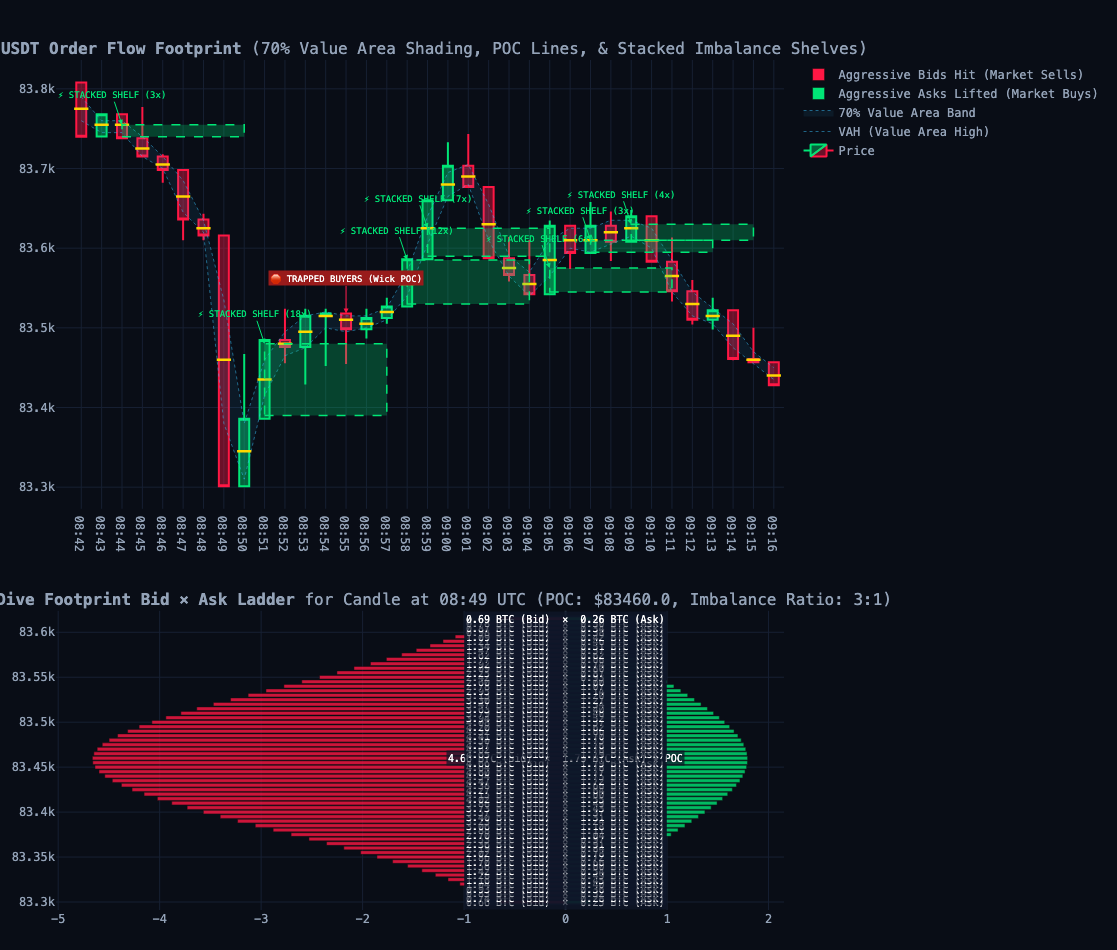

Footprint calculation and interactive visualization complete!


In [8]:
# ==============================================================================================
# Google Colab: Microstructure Volume Footprint, Value Area (70%), POC & Stacked Imbalance Visualizer
# ==============================================================================================

# In Google Colab, plotly and pandas are pre-installed. If not, uncomment the next line:
# !pip install plotly requests pandas numpy

import json
import urllib.request
import numpy as np
import pandas as pd
from datetime import datetime
import plotly.graph_objects as go
from plotly.subplots import make_subplots

def fetch_binance_klines(symbol='BTCUSDT', interval='1m', limit=35):
    url = f"https://api.binance.com/api/v3/klines?symbol={symbol}&interval={interval}&limit={limit}"
    req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
    with urllib.request.urlopen(req) as resp:
        raw = json.loads(resp.read().decode())
    return raw

def compute_footprint_features(raw_klines, tick_size=5.0, imbalance_ratio=3.0, value_area_pct=0.70):
    candles = []
    
    for row in raw_klines:
        t_open = int(row[0])
        dt_str = datetime.utcfromtimestamp(t_open / 1000.0).strftime('%H:%M')
        open_p = float(row[1])
        high_p = float(row[2])
        low_p = float(row[3])
        close_p = float(row[4])
        vol = float(row[5])
        taker_buy = float(row[9])
        taker_sell = max(0.0, vol - taker_buy)

        # Price binning into discrete ticks (e.g. $5 ticks)
        p_min = np.floor(low_p / tick_size) * tick_size
        p_max = np.ceil(high_p / tick_size) * tick_size
        count = max(1, int(round((p_max - p_min) / tick_size)))

        # Constrained distribution using actual Binance taker buy/sell volumes
        center_p = (open_p + close_p) * 0.5
        weights = []
        for i in range(count):
            p = p_min + i * tick_size
            dist = abs((p - center_p) / max(1e-4, p_max - p_min))
            w = np.exp(-dist * dist * 8.0)
            weights.append(max(0.08, w))
        weights = np.array(weights)
        weights /= weights.sum()

        levels = []
        for i in range(count):
            p = p_min + i * tick_size
            buy_v = taker_buy * weights[i]
            sell_v = taker_sell * weights[i]
            levels.append({'price': p, 'buy': buy_v, 'sell': sell_v})

        # 1. Point of Control (POC)
        poc_idx = 0
        max_vol = -1.0
        total_vol = 0.0
        for i, lvl in enumerate(levels):
            v = lvl['buy'] + lvl['sell']
            total_vol += v
            if v > max_vol:
                max_vol = v
                poc_idx = i
        poc_p = levels[poc_idx]['price']

        # 2. 70% Value Area Outward Greedy Expansion from POC
        va_cum = max_vol
        va_lo = poc_idx
        va_hi = poc_idx
        target_va = total_vol * value_area_pct

        while va_cum < target_va and (va_lo > 0 or va_hi + 1 < count):
            lo_v = (levels[va_lo - 1]['buy'] + levels[va_lo - 1]['sell']) if va_lo > 0 else -1.0
            hi_v = (levels[va_hi + 1]['buy'] + levels[va_hi + 1]['sell']) if va_hi + 1 < count else -1.0
            if lo_v < 0 and hi_v < 0:
                break
            if hi_v >= lo_v:
                va_hi += 1
                va_cum += hi_v
            else:
                va_lo -= 1
                va_cum += lo_v

        val_p = levels[va_lo]['price']
        vah_p = levels[va_hi]['price']

        # 3. True Diagonal Imbalances (Ask at tick i vs Bid at tick i-1 >= 3.0)
        for i in range(count):
            is_buy_imb = (levels[i]['buy'] / levels[i - 1]['sell'] >= imbalance_ratio) if (i > 0 and levels[i - 1]['sell'] > 0.01) else False
            is_sell_imb = (levels[i]['sell'] / levels[i + 1]['buy'] >= imbalance_ratio) if (i + 1 < count and levels[i + 1]['buy'] > 0.01) else False
            levels[i]['is_buy_imb'] = is_buy_imb
            levels[i]['is_sell_imb'] = is_sell_imb

        # 4. Stacked Imbalance Zones (>= 3 contiguous adjacent levels)
        stacked_buy_zones = []
        cur_stack = 0
        stack_start = levels[0]['price']
        for lvl in levels:
            if lvl['is_buy_imb']:
                if cur_stack == 0:
                    stack_start = lvl['price']
                cur_stack += 1
            else:
                if cur_stack >= 3:
                    stacked_buy_zones.append((stack_start, lvl['price'], cur_stack))
                cur_stack = 0
        if cur_stack >= 3:
            stacked_buy_zones.append((stack_start, levels[-1]['price'], cur_stack))

        # 5. Trapped Volume at Wicks (Absorption Top)
        candle_range = max(1e-4, high_p - low_p)
        poc_rel = (poc_p - low_p) / candle_range
        trapped_buyers = (poc_rel >= 0.80 and close_p < poc_p)

        candles.append({
            'time_str': dt_str,
            'timestamp': t_open,
            'open': open_p, 'high': high_p, 'low': low_p, 'close': close_p,
            'vol': vol, 'delta': taker_buy - taker_sell,
            'poc': poc_p, 'val': val_p, 'vah': vah_p,
            'stacked_buy': stacked_buy_zones,
            'trapped_buyers': trapped_buyers,
            'poc_rel': poc_rel,
            'levels': levels
        })

    return candles

def plot_interactive_footprint(candles):
    df = pd.DataFrame(candles)
    n = len(df)
    times = df['time_str'].tolist()

    # Pick the highest volume candle to render the deep-dive footprint ladder
    focus_idx = int(np.argmax(df['vol']))
    focus_c = candles[focus_idx]

    fig = make_subplots(
        rows=2, cols=1,
        shared_xaxes=False,
        vertical_spacing=0.12,
        subplot_titles=[
            f"<b>BTCUSDT Order Flow Footprint</b> (70% Value Area Shading, POC Lines, & Stacked Imbalance Shelves)",
            f"<b>Deep-Dive Footprint Bid × Ask Ladder</b> for Candle at {focus_c['time_str']} UTC (POC: ${focus_c['poc']:.1f}, Imbalance Ratio: 3:1)"
        ],
        row_heights=[0.60, 0.40]
    )

    # 1. Main Candlesticks
    fig.add_trace(go.Candlestick(
        x=times,
        open=df['open'], high=df['high'], low=df['low'], close=df['close'],
        name='Price',
        increasing_line_color='#00E676', decreasing_line_color='#FF1744',
        increasing_fillcolor='rgba(0, 230, 118, 0.4)', decreasing_fillcolor='rgba(255, 23, 68, 0.4)'
    ), row=1, col=1)

    # 2. 70% Value Area Envelopes (VAH and VAL)
    fig.add_trace(go.Scatter(
        x=times, y=df['vah'],
        line=dict(color='rgba(56, 189, 248, 0.5)', width=1, dash='dot'),
        name='VAH (Value Area High)',
        showlegend=True
    ), row=1, col=1)

    fig.add_trace(go.Scatter(
        x=times, y=df['val'],
        line=dict(color='rgba(56, 189, 248, 0.5)', width=1, dash='dot'),
        fill='tonexty',
        fillcolor='rgba(56, 189, 248, 0.08)',
        name='70% Value Area Band',
        showlegend=True
    ), row=1, col=1)

    # 3. Gold POC Lines on each candle
    for i, c in enumerate(candles):
        fig.add_shape(
            type="line",
            x0=i - 0.35, x1=i + 0.35,
            y0=c['poc'], y1=c['poc'],
            line=dict(color="#FFD700", width=2.5),
            row=1, col=1
        )

    # 4. Stacked Imbalance Support Shelves (Extended forward)
    for i, c in enumerate(candles):
        if c['stacked_buy']:
            for s_start, s_end, count in c['stacked_buy']:
                fig.add_shape(
                    type="rect",
                    x0=i, x1=min(n - 1, i + 6),
                    y0=s_start, y1=s_end,
                    fillcolor="rgba(0, 230, 118, 0.25)",
                    line=dict(color="#00E676", width=1.5, dash="dash"),
                    row=1, col=1
                )
                fig.add_annotation(
                    x=i, y=s_end,
                    text=f"⚡ STACKED SHELF ({count}x)",
                    showarrow=True, arrowhead=2, arrowcolor="#00E676",
                    font=dict(size=9, color="#00E676"),
                    row=1, col=1
                )

    # 5. Trapped Buyers / Wick Trap Annotations
    for i, c in enumerate(candles):
        if c['trapped_buyers']:
            fig.add_annotation(
                x=times[i], y=c['high'],
                text="🛑 TRAPPED BUYERS (Wick POC)",
                showarrow=True, arrowhead=2, arrowcolor="#FF1744", ax=0, ay=-35,
                bgcolor="#991B1B", font=dict(size=9, color="#FFFFFF"),
                row=1, col=1
            )

    # 6. Deep-Dive Footprint Bid × Ask Ladder for Focus Candle (Sub-Plot 2)
    flvls = focus_c['levels']
    prices = [lvl['price'] for lvl in flvls]
    buy_vols = [lvl['buy'] for lvl in flvls]
    sell_vols = [-lvl['sell'] for lvl in flvls] # Negative for visual bid/ask split

    text_labels = []
    for lvl in flvls:
        imb_tag = ""
        if lvl['is_buy_imb']: imb_tag = " [3:1 BUY IMB ⚡]"
        elif lvl['is_sell_imb']: imb_tag = " [3:1 SELL IMB 🛑]"
        poc_tag = " ★ POC" if abs(lvl['price'] - focus_c['poc']) < 1e-4 else ""
        text_labels.append(f"{lvl['sell']:.2f} BTC (Bid)  ×  {lvl['buy']:.2f} BTC (Ask){imb_tag}{poc_tag}")

    fig.add_trace(go.Bar(
        y=prices, x=buy_vols, orientation='h',
        name='Aggressive Asks Lifted (Market Buys)',
        marker=dict(color='#00E676', opacity=0.8),
        hovertext=[f"Price ${p:.1f}: Buy Vol = {b:.2f} BTC" for p, b in zip(prices, buy_vols)],
        hoverinfo='text'
    ), row=2, col=1)

    fig.add_trace(go.Bar(
        y=prices, x=sell_vols, orientation='h',
        name='Aggressive Bids Hit (Market Sells)',
        marker=dict(color='#FF1744', opacity=0.8),
        hovertext=[f"Price ${p:.1f}: Sell Vol = {-s:.2f} BTC" for p, s in zip(prices, sell_vols)],
        hoverinfo='text'
    ), row=2, col=1)

    for p, txt in zip(prices, text_labels):
        fig.add_annotation(
            x=0, y=p, text=txt,
            showarrow=False,
            font=dict(size=10, color="#FFFFFF", family="monospace"),
            bgcolor="rgba(15, 23, 42, 0.75)",
            row=2, col=1
        )

    # Dark Theme Layout
    fig.update_layout(
        template='plotly_dark',
        height=950,
        barmode='relative',
        paper_bgcolor='#090d16',
        plot_bgcolor='#090d16',
        font=dict(color='#94a3b8', family='JetBrains Mono, monospace'),
        margin=dict(l=40, r=40, t=60, b=40),
        xaxis_rangeslider_visible=False
    )
    
    fig.update_xaxes(gridcolor='#172033')
    fig.update_yaxes(gridcolor='#172033')

    fig.show()

if __name__ == '__main__':
    print("Fetching live Binance klines and computing footprint order flow...")
    raw = fetch_binance_klines(symbol='BTCUSDT', interval='1m', limit=35)
    candles = compute_footprint_features(raw, tick_size=5.0, imbalance_ratio=3.0, value_area_pct=0.70)
    plot_interactive_footprint(candles)
    print("Footprint calculation and interactive visualization complete!")

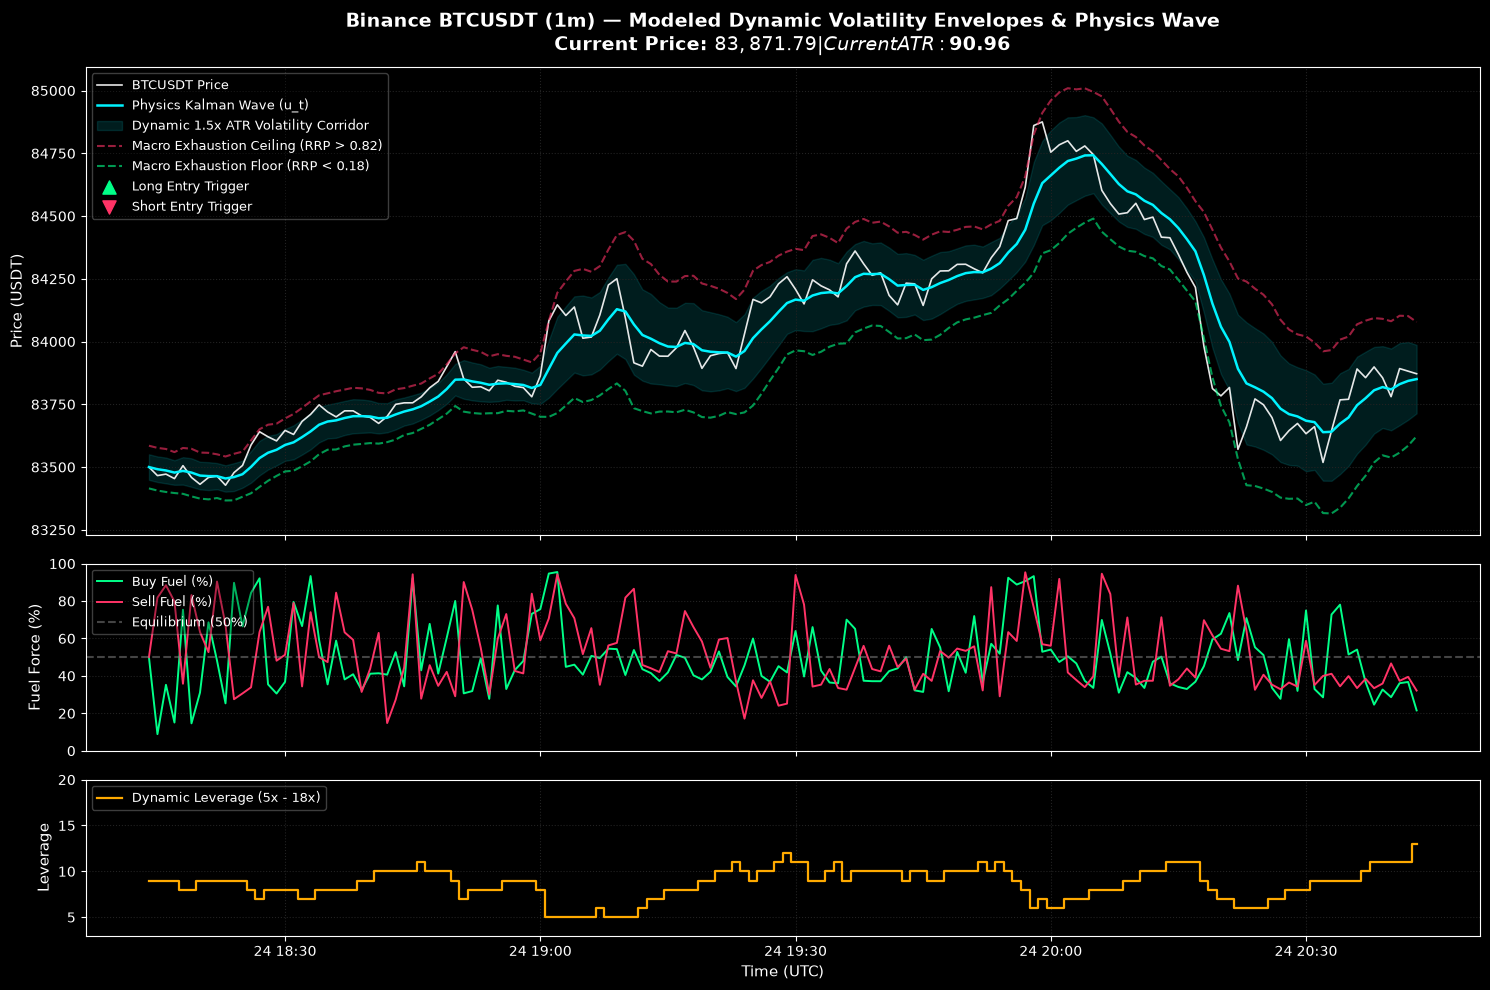

In [16]:
# ==============================================================================
# MASTER MODEL v5.0: DYNAMIC VOLATILITY & PHYSICS ENVELOPE VISUALIZER
# Copy and paste this entire block directly into a single Jupyter Notebook cell
# ==============================================================================
%matplotlib inline
import urllib.request
import json
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# 1. Fetch Real-time 1m BTCUSDT Candles from Binance Public API
url = "https://api.binance.com/api/v3/klines?symbol=BTCUSDT&interval=1m&limit=150"
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
raw_data = json.loads(urllib.request.urlopen(req).read().decode('utf-8'))

times = [datetime.fromtimestamp(r[0] / 1000) for r in raw_data]
opens = np.array([float(r[1]) for r in raw_data])
highs = np.array([float(r[2]) for r in raw_data])
lows = np.array([float(r[3]) for r in raw_data])
closes = np.array([float(r[4]) for r in raw_data])
volumes = np.array([float(r[5]) for r in raw_data])
taker_buys = np.array([float(r[9]) for r in raw_data])
taker_sells = np.maximum(0.0, volumes - taker_buys)
n = len(closes)

# 2. Causal Dynamic Volatility (ATR) & Rolling 20-bar Baseline
tr = np.zeros(n)
tr[0] = highs[0] - lows[0]
for i in range(1, n):
    tr[i] = max(highs[i] - lows[i], abs(highs[i] - closes[i - 1]), abs(lows[i] - closes[i - 1]))

alpha_atr = 2.0 / (14 + 1)
atr = np.zeros(n)
atr[0] = tr[0]
for i in range(1, n):
    atr[i] = alpha_atr * tr[i] + (1 - alpha_atr) * atr[i - 1]

# Rolling 20-period average ATR to detect volatility regimes
atr_avg20 = np.zeros(n)
for i in range(n):
    atr_avg20[i] = np.mean(atr[max(0, i - 19):i + 1])

# 3. Causal Decoupled Normalization (Buy & Sell Fuel 0-100%)
decay = 0.08
mu_buy, var_buy = taker_buys[0], 1.0
mu_sell, var_sell = taker_sells[0], 1.0
norm_buy = np.zeros(n)
norm_sell = np.zeros(n)

for i in range(n):
    diff_b = taker_buys[i] - mu_buy
    mu_buy += decay * diff_b
    var_buy = (1 - decay) * var_buy + decay * (diff_b ** 2)
    z_buy = (taker_buys[i] - mu_buy) / (np.sqrt(var_buy) + 1e-6)
    norm_buy[i] = 100.0 / (1.0 + np.exp(-z_buy))

    diff_s = taker_sells[i] - mu_sell
    mu_sell += decay * diff_s
    var_sell = (1 - decay) * var_sell + decay * (diff_s ** 2)
    z_sell = (taker_sells[i] - mu_sell) / (np.sqrt(var_sell) + 1e-6)
    norm_sell[i] = 100.0 / (1.0 + np.exp(-z_sell))

# 4. Physics Kalman Wave (Kinematic Velocity & Acceleration)
pos = closes[0]
vel = 0.0
wave_pos = np.zeros(n)
wave_vel = np.zeros(n)

for i in range(n):
    net_force = (norm_buy[i] - norm_sell[i]) / 50.0
    u = 0.003 * net_force * atr[i]
    pos = pos + vel + 0.5 * u
    vel = 0.85 * vel + u
    kalman_gain = 0.25
    pos = pos + kalman_gain * (closes[i] - pos)
    wave_pos[i] = pos
    wave_vel[i] = vel

# 5. Dynamic Volatility Envelope Bands around Price
upper_vol_band = wave_pos + (1.5 * atr)
lower_vol_band = wave_pos - (1.5 * atr)
safe_ceiling = wave_pos + (2.5 * atr)
safe_floor = wave_pos - (2.5 * atr)

# 6. Dynamic Volatility Leverage Gauge (5x to 18x)
dyn_leverage = np.zeros(n)
for i in range(n):
    vol_ratio = atr_avg20[i] / max(atr[i], atr_avg20[i] * 0.25)
    # Higher volatility compresses leverage down; tight compression expands leverage safely
    raw_lev = 9.0 * vol_ratio
    dyn_leverage[i] = np.clip(np.round(raw_lev), 5, 18)

# ==============================================================================
# 7. Multi-Panel Visualization
# ==============================================================================
plt.style.use('dark_background')
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 10), gridspec_kw={'height_ratios': [3, 1.2, 1]}, sharex=True)

# --- Top Panel: Price, Physics Wave, and Volatility Envelopes ---
ax1.plot(times, closes, label='BTCUSDT Price', color='#ffffff', alpha=0.9, lw=1.2)
ax1.plot(times, wave_pos, label='Physics Kalman Wave (u_t)', color='#00f3ff', lw=1.8)

# Fill dynamic volatility corridor
ax1.fill_between(times, lower_vol_band, upper_vol_band, color='#00f3ff', alpha=0.12, label='Dynamic 1.5x ATR Volatility Corridor')
ax1.plot(times, safe_ceiling, '--', color='#ff3366', alpha=0.6, label='Macro Exhaustion Ceiling (RRP > 0.82)')
ax1.plot(times, safe_floor, '--', color='#00ff88', alpha=0.6, label='Macro Exhaustion Floor (RRP < 0.18)')

# Mark Long & Short Pullback Triggers
long_signals = (norm_buy >= 50.0) & (norm_buy > norm_sell) & (wave_vel > 2.0) & (closes <= upper_vol_band)
short_signals = (norm_sell >= 50.0) & (norm_sell > norm_buy) & (wave_vel < -2.0) & (closes >= lower_vol_band)

ax1.scatter([times[i] for i in range(n) if long_signals[i]], 
            [lows[i] - 15 for i in range(n) if long_signals[i]], 
            marker='^', color='#00ff88', s=90, label='Long Entry Trigger', zorder=5)
ax1.scatter([times[i] for i in range(n) if short_signals[i]], 
            [highs[i] + 15 for i in range(n) if short_signals[i]], 
            marker='v', color='#ff3366', s=90, label='Short Entry Trigger', zorder=5)

ax1.set_title(f"Binance BTCUSDT (1m) — Modeled Dynamic Volatility Envelopes & Physics Wave\nCurrent Price: ${closes[-1]:,.2f} | Current ATR: ${atr[-1]:.2f}", fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel("Price (USDT)", fontsize=11)
ax1.legend(loc='upper left', framealpha=0.3, fontsize=9)
ax1.grid(color='#222222', linestyle=':', lw=0.8)

# --- Middle Panel: Normalized Order Flow Fuel Gauge ---
ax2.plot(times, norm_buy, label='Buy Fuel (%)', color='#00ff88', lw=1.4)
ax2.plot(times, norm_sell, label='Sell Fuel (%)', color='#ff3366', lw=1.4)
ax2.axhline(50, color='#888888', linestyle='--', alpha=0.5, label='Equilibrium (50%)')
ax2.set_ylabel("Fuel Force (%)", fontsize=11)
ax2.set_ylim(0, 100)
ax2.legend(loc='upper left', framealpha=0.3, fontsize=9)
ax2.grid(color='#222222', linestyle=':', lw=0.8)

# --- Bottom Panel: Dynamic Volatility Leverage Gauge ---
ax3.step(times, dyn_leverage, label='Dynamic Leverage (5x - 18x)', color='#ffaa00', lw=1.6, where='mid')
ax3.set_ylabel("Leverage", fontsize=11)
ax3.set_ylim(3, 20)
ax3.legend(loc='upper left', framealpha=0.3, fontsize=9)
ax3.grid(color='#222222', linestyle=':', lw=0.8)
ax3.set_xlabel("Time (UTC)", fontsize=11)

plt.tight_layout()
plt.show()

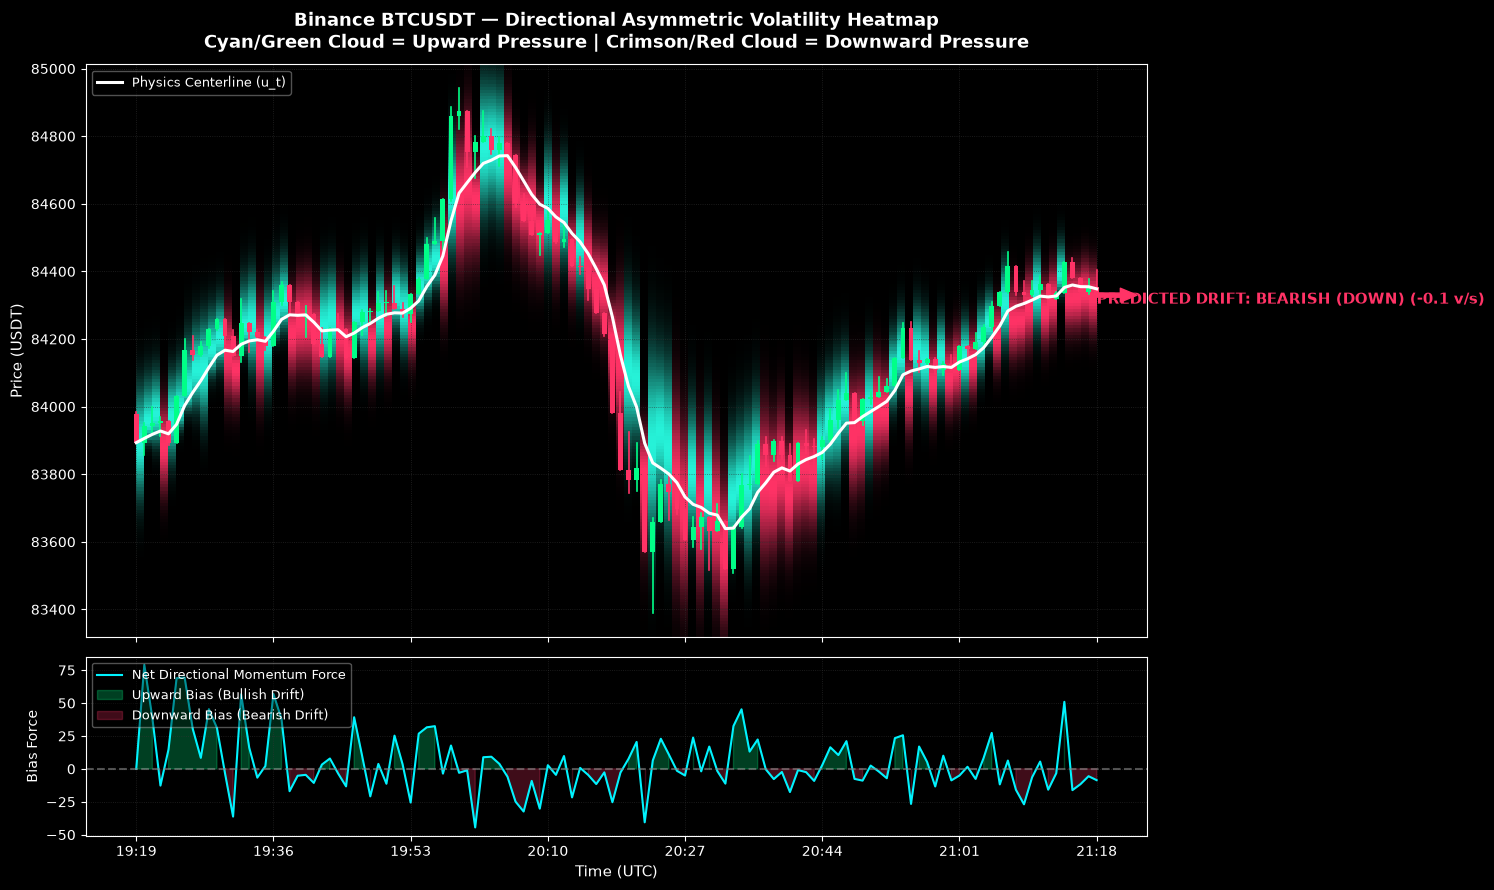

In [19]:
# ==============================================================================
# BTCUSDT DIRECTIONAL ASYMMETRIC VOLATILITY HEATMAP & PREDICTED DRIFT
# Run this in a single Jupyter Notebook cell (Pure NumPy — No SciPy Required)
# ==============================================================================
%matplotlib inline
import urllib.request
import json
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# Accurate Standard Normal PDF & CDF in pure NumPy
def norm_pdf(x):
    return np.exp(-0.5 * x**2) / np.sqrt(2.0 * np.pi)

def norm_cdf(x):
    return 1.0 / (1.0 + np.exp(-1.702 * x))

# 1. Fetch Real-time 1m BTCUSDT Candles from Binance
url = "https://api.binance.com/api/v3/klines?symbol=BTCUSDT&interval=1m&limit=120"
req = urllib.request.Request(url, headers={'User-Agent': 'Mozilla/5.0'})
raw = json.loads(urllib.request.urlopen(req).read().decode('utf-8'))

times = [datetime.fromtimestamp(r[0] / 1000) for r in raw]
opens = np.array([float(r[1]) for r in raw])
highs = np.array([float(r[2]) for r in raw])
lows = np.array([float(r[3]) for r in raw])
closes = np.array([float(r[4]) for r in raw])
volumes = np.array([float(r[5]) for r in raw])
taker_buys = np.array([float(r[9]) for r in raw])
taker_sells = np.maximum(0.0, volumes - taker_buys)
n = len(closes)

# 2. Causal Dynamic Volatility (ATR)
tr = np.zeros(n)
tr[0] = highs[0] - lows[0]
for i in range(1, n):
    tr[i] = max(highs[i] - lows[i], abs(highs[i] - closes[i - 1]), abs(lows[i] - closes[i - 1]))

alpha_atr = 2.0 / (14 + 1)
atr = np.zeros(n)
atr[0] = tr[0]
for i in range(1, n):
    atr[i] = alpha_atr * tr[i] + (1 - alpha_atr) * atr[i - 1]

# 3. Causal Decoupled Normalization (Buy & Sell Fuel 0-100%)
decay = 0.08
mu_buy, var_buy = taker_buys[0], 1.0
mu_sell, var_sell = taker_sells[0], 1.0
norm_buy = np.zeros(n)
norm_sell = np.zeros(n)

for i in range(n):
    diff_b = taker_buys[i] - mu_buy
    mu_buy += decay * diff_b
    var_buy = (1 - decay) * var_buy + decay * (diff_b ** 2)
    norm_buy[i] = 100.0 / (1.0 + np.exp(-(taker_buys[i] - mu_buy) / (np.sqrt(var_buy) + 1e-6)))

    diff_s = taker_sells[i] - mu_sell
    mu_sell += decay * diff_s
    var_sell = (1 - decay) * var_sell + decay * (diff_s ** 2)
    norm_sell[i] = 100.0 / (1.0 + np.exp(-(taker_sells[i] - mu_sell) / (np.sqrt(var_sell) + 1e-6)))

# 4. Physics Kalman Wave (Kinematic Velocity & Acceleration)
pos = closes[0]
vel = 0.0
wave_pos = np.zeros(n)
wave_vel = np.zeros(n)

for i in range(n):
    net_force = (norm_buy[i] - norm_sell[i]) / 50.0
    u = 0.003 * net_force * atr[i]
    pos = pos + vel + 0.5 * u
    vel = 0.85 * vel + u
    pos = pos + 0.25 * (closes[i] - pos)
    wave_pos[i] = pos
    wave_vel[i] = vel

# 5. DIRECTIONAL ASYMMETRIC VOLATILITY HEATMAP (Skewed by Order Flow Force & Wave Velocity)
min_p = np.min(lows) - 70
max_p = np.max(highs) + 70
p_grid = np.linspace(min_p, max_p, 180)

# RGB Heatmap Matrix: Red = downward sell pressure, Green = upward buy pressure
heat_rgb = np.zeros((len(p_grid), n, 3))

for t in range(n):
    c_p = wave_pos[t]
    sigma = max(10.0, atr[t] * 1.3)
    v_norm = np.clip(wave_vel[t] / 15.0, -1.5, 1.5)
    f_net = (norm_buy[t] - norm_sell[t]) / 50.0
    
    # Skew parameter: alpha > 0 tilts upward, alpha < 0 tilts downward
    skew_alpha = 2.5 * (f_net + 0.8 * v_norm)
    
    # Skew-Normal Probability Density function: 2 * phi(z) * Phi(alpha * z)
    z = (p_grid - c_p) / sigma
    density = 2.0 * norm_pdf(z) * norm_cdf(skew_alpha * z)
    density = density / (np.max(density) + 1e-6)

    # Color Mapping: Green/Cyan for Bullish Skew, Red/Crimson for Bearish Skew
    intensity = density ** 1.3
    if skew_alpha >= 0:
        heat_rgb[:, t, 0] = intensity * 0.15 # Red
        heat_rgb[:, t, 1] = intensity * 0.95 # Green
        heat_rgb[:, t, 2] = intensity * 0.85 # Blue/Cyan
    else:
        heat_rgb[:, t, 0] = intensity * 1.00 # Red/Crimson
        heat_rgb[:, t, 1] = intensity * 0.20 # Green
        heat_rgb[:, t, 2] = intensity * 0.40 # Magenta

# 6. Multi-Panel Visualization
plt.style.use('dark_background')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(15, 9), gridspec_kw={'height_ratios': [3.2, 1]}, sharex=True)

# TOP PANEL: Directional Skew Heatmap Cloud
extent = [0, n - 1, min_p, max_p]
ax1.imshow(heat_rgb, origin='lower', aspect='auto', extent=extent, zorder=1)

# Draw Candlesticks
for i in range(n):
    color = '#00ff88' if closes[i] >= opens[i] else '#ff3366'
    ax1.plot([i, i], [lows[i], highs[i]], color=color, lw=1.2, zorder=3)
    body_low = min(opens[i], closes[i])
    body_high = max(opens[i], closes[i])
    ax1.bar(i, max(1.5, body_high - body_low), bottom=body_low, color=color, width=0.6, zorder=4)

# Physics Wave Centerline
ax1.plot(range(n), wave_pos, color='#ffffff', lw=2.2, label='Physics Centerline (u_t)', zorder=5)

# Forward Directional Vector at current candle
last_v = wave_vel[-1]
last_p = closes[-1]
target_vector = last_p + (last_v * 5.0)
target_color = '#00ff88' if last_v >= 0 else '#ff3366'
trend_label = f"PREDICTED DRIFT: {'BULLISH (UP)' if last_v >= 0 else 'BEARISH (DOWN)'} ({last_v:+.1f} v/s)"

ax1.annotate('', xy=(n - 1 + 5, target_vector), xytext=(n - 1, last_p),
             arrowprops=dict(facecolor=target_color, edgecolor=target_color, width=3, headwidth=10), zorder=8)
ax1.text(n - 1, target_vector + (15 if last_v >= 0 else -25), trend_label, color=target_color, fontweight='bold', fontsize=11, zorder=8)

ax1.set_ylim(min_p, max_p)
ax1.set_title(f"Binance BTCUSDT — Directional Asymmetric Volatility Heatmap\nCyan/Green Cloud = Upward Pressure | Crimson/Red Cloud = Downward Pressure", fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel("Price (USDT)", fontsize=11)
ax1.legend(loc='upper left', framealpha=0.4, fontsize=9)
ax1.grid(color='#333333', linestyle=':', lw=0.6, alpha=0.7)

# BOTTOM PANEL: Directional Momentum Force
skew_series = np.array([(norm_buy[i] - norm_sell[i]) + 2.5 * wave_vel[i] for i in range(n)])
ax2.plot(range(n), skew_series, color='#00f3ff', lw=1.5, label='Net Directional Momentum Force')
ax2.axhline(0, color='#888888', linestyle='--', alpha=0.6)
ax2.fill_between(range(n), 0, skew_series, where=(skew_series >= 0), color='#00ff88', alpha=0.25, label='Upward Bias (Bullish Drift)')
ax2.fill_between(range(n), 0, skew_series, where=(skew_series < 0), color='#ff3366', alpha=0.25, label='Downward Bias (Bearish Drift)')

tick_idx = np.linspace(0, n - 1, 8, dtype=int)
ax2.set_xticks(tick_idx)
ax2.set_xticklabels([times[i].strftime('%H:%M') for i in tick_idx])
ax2.set_xlabel("Time (UTC)", fontsize=11)
ax2.set_ylabel("Bias Force", fontsize=10)
ax2.legend(loc='upper left', framealpha=0.4, fontsize=9)
ax2.grid(color='#333333', linestyle=':', lw=0.6, alpha=0.7)

plt.tight_layout()
plt.show()

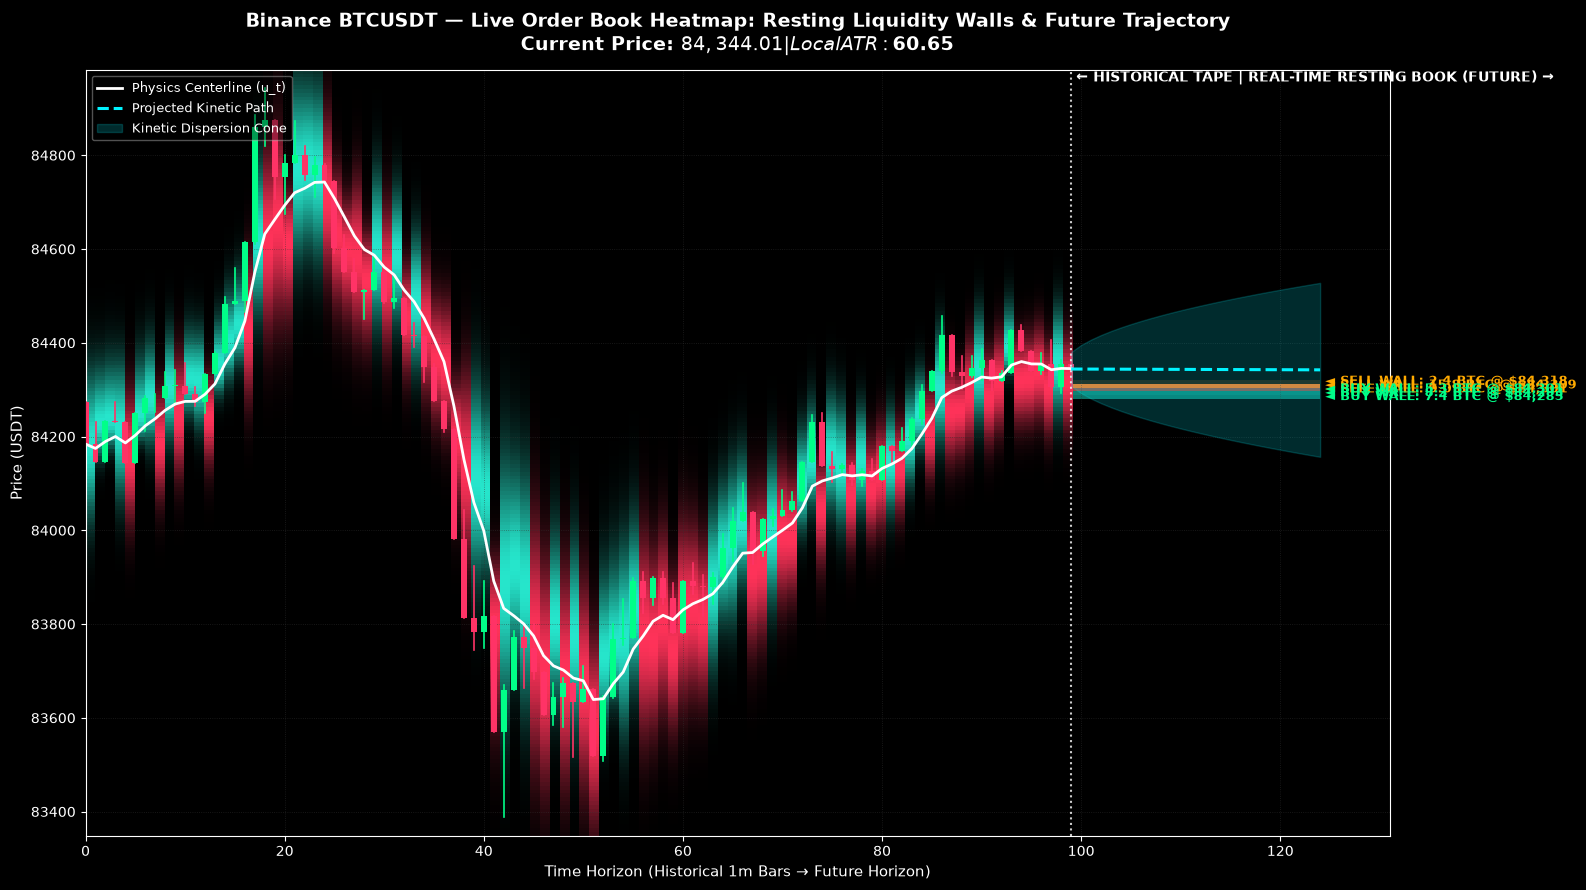

In [22]:
# ==============================================================================
# BTCUSDT LIVE ORDER BOOK HEATMAP: RESTING WALLS & FUTURE TRAJECTORY (FIXED)
# ==============================================================================
%matplotlib inline
import urllib.request
import json
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# Standard Normal PDF & CDF in pure NumPy
def norm_pdf(x):
    return np.exp(-0.5 * x**2) / np.sqrt(2.0 * np.pi)

def norm_cdf(x):
    return 1.0 / (1.0 + np.exp(-1.702 * x))

# 1. Fetch Real-time 1m Klines
url_klines = "https://api.binance.com/api/v3/klines?symbol=BTCUSDT&interval=1m&limit=100"
req_k = urllib.request.Request(url_klines, headers={'User-Agent': 'Mozilla/5.0'})
raw_k = json.loads(urllib.request.urlopen(req_k, timeout=6).read().decode('utf-8'))

# 2. Fetch Live Resting L2 Depth (Fixed: limit=100 is Binance's legal parameter)
raw_depth = None
for depth_url in [
    "https://fapi.binance.com/fapi/v1/depth?symbol=BTCUSDT&limit=100",
    "https://api.binance.com/api/v3/depth?symbol=BTCUSDT&limit=100"
]:
    try:
        req_d = urllib.request.Request(depth_url, headers={'User-Agent': 'Mozilla/5.0'})
        raw_depth = json.loads(urllib.request.urlopen(req_d, timeout=5).read().decode('utf-8'))
        break
    except Exception:
        continue

if raw_depth is None:
    raise RuntimeError("Could not connect to Binance Depth API. Check your internet connection.")

times = [datetime.fromtimestamp(r[0] / 1000) for r in raw_k]
opens = np.array([float(r[1]) for r in raw_k])
highs = np.array([float(r[2]) for r in raw_k])
lows = np.array([float(r[3]) for r in raw_k])
closes = np.array([float(r[4]) for r in raw_k])
volumes = np.array([float(r[5]) for r in raw_k])
taker_buys = np.array([float(r[9]) for r in raw_k])
taker_sells = np.maximum(0.0, volumes - taker_buys)
n = len(closes)

# Parse Resting Bids & Asks
book_bids = np.array([[float(p), float(q)] for p, q in raw_depth['bids']])
book_asks = np.array([[float(p), float(q)] for p, q in raw_depth['asks']])

# 3. Dynamic Volatility (ATR)
tr = np.zeros(n)
tr[0] = highs[0] - lows[0]
for i in range(1, n):
    tr[i] = max(highs[i] - lows[i], abs(highs[i] - closes[i - 1]), abs(lows[i] - closes[i - 1]))

alpha_atr = 2.0 / (14 + 1)
atr = np.zeros(n)
atr[0] = tr[0]
for i in range(1, n):
    atr[i] = alpha_atr * tr[i] + (1 - alpha_atr) * atr[i - 1]

# 4. Causal Decoupled Normalization (Buy/Sell Fuel)
decay = 0.08
mu_b, var_b = taker_buys[0], 1.0
mu_s, var_s = taker_sells[0], 1.0
norm_buy, norm_sell = np.zeros(n), np.zeros(n)

for i in range(n):
    db = taker_buys[i] - mu_b
    mu_b += decay * db
    var_b = (1 - decay) * var_b + decay * (db ** 2)
    norm_buy[i] = 100.0 / (1.0 + np.exp(-(taker_buys[i] - mu_b) / (np.sqrt(var_b) + 1e-6)))

    ds = taker_sells[i] - mu_s
    mu_s += decay * ds
    var_s = (1 - decay) * var_s + decay * (ds ** 2)
    norm_sell[i] = 100.0 / (1.0 + np.exp(-(taker_sells[i] - mu_s) / (np.sqrt(var_s) + 1e-6)))

# 5. Physics Kalman Wave
pos = closes[0]
vel = 0.0
wave_pos, wave_vel = np.zeros(n), np.zeros(n)

for i in range(n):
    net_force = (norm_buy[i] - norm_sell[i]) / 50.0
    u = 0.003 * net_force * atr[i]
    pos = pos + vel + 0.5 * u
    vel = 0.85 * vel + u
    pos = pos + 0.25 * (closes[i] - pos)
    wave_pos[i], wave_vel[i] = pos, vel

# 6. Future Projection Horizon: 25 Bars ahead of Current Price
future_bars = 25
total_len = n + future_bars

min_p = min(np.min(lows), np.min(book_bids[:40, 0])) - 40
max_p = max(np.max(highs), np.max(book_asks[:40, 0])) + 40
p_grid = np.linspace(min_p, max_p, 200)

# 7. Combined Heatmap: Historical Skew Cloud + Future Resting Order Walls
heat_rgb = np.zeros((len(p_grid), total_len, 3))

# Left Half: Historical Asymmetric Directional Cloud
for t in range(n):
    c_p = wave_pos[t]
    sigma = max(10.0, atr[t] * 1.3)
    v_norm = np.clip(wave_vel[t] / 15.0, -1.5, 1.5)
    f_net = (norm_buy[t] - norm_sell[t]) / 50.0
    skew_alpha = 2.5 * (f_net + 0.8 * v_norm)

    z = (p_grid - c_p) / sigma
    density = 2.0 * norm_pdf(z) * norm_cdf(skew_alpha * z)
    density = density / (np.max(density) + 1e-6)
    intensity = density ** 1.3

    if skew_alpha >= 0:
        heat_rgb[:, t, 0] = intensity * 0.15 # Bullish Green
        heat_rgb[:, t, 1] = intensity * 0.90
        heat_rgb[:, t, 2] = intensity * 0.80
    else:
        heat_rgb[:, t, 0] = intensity * 1.00 # Bearish Crimson
        heat_rgb[:, t, 1] = intensity * 0.20
        heat_rgb[:, t, 2] = intensity * 0.35

# Right Half: Future Resting Liquidity Walls from Live L2 Book
bin_size = (max_p - min_p) / len(p_grid)
wall_bids = np.zeros(len(p_grid))
wall_asks = np.zeros(len(p_grid))

for p, q in book_bids:
    idx = int((p - min_p) / bin_size)
    if 0 <= idx < len(p_grid):
        wall_bids[idx] += q

for p, q in book_asks:
    idx = int((p - min_p) / bin_size)
    if 0 <= idx < len(p_grid):
        wall_asks[idx] += q

max_wall = max(np.max(wall_bids), np.max(wall_asks), 1.0)
norm_bids = wall_bids / max_wall
norm_asks = wall_asks / max_wall

for t in range(n, total_len):
    # Asks: Glowing Orange/Red Resting Sell Walls
    heat_rgb[:, t, 0] = np.maximum(heat_rgb[:, t, 0], norm_asks * 1.0)
    heat_rgb[:, t, 1] = np.maximum(heat_rgb[:, t, 1], norm_asks * 0.45)
    heat_rgb[:, t, 2] = np.maximum(heat_rgb[:, t, 2], norm_asks * 0.10)

    # Bids: Glowing Cyan/Emerald Resting Buy Walls
    heat_rgb[:, t, 0] = np.maximum(heat_rgb[:, t, 0], norm_bids * 0.10)
    heat_rgb[:, t, 1] = np.maximum(heat_rgb[:, t, 1], norm_bids * 0.95)
    heat_rgb[:, t, 2] = np.maximum(heat_rgb[:, t, 2], norm_bids * 0.85)

# 8. Rendering
plt.style.use('dark_background')
fig, ax1 = plt.subplots(figsize=(16, 9))

extent = [0, total_len - 1, min_p, max_p]
ax1.imshow(heat_rgb, origin='lower', aspect='auto', extent=extent, zorder=1)

# Draw Candlesticks
for i in range(n):
    color = '#00ff88' if closes[i] >= opens[i] else '#ff3366'
    ax1.plot([i, i], [lows[i], highs[i]], color=color, lw=1.2, zorder=3)
    body_low = min(opens[i], closes[i])
    body_high = max(opens[i], closes[i])
    ax1.bar(i, max(1.5, body_high - body_low), bottom=body_low, color=color, width=0.6, zorder=4)

# Physics Wave Centerline
ax1.plot(range(n), wave_pos, color='#ffffff', lw=2.0, label='Physics Centerline (u_t)', zorder=5)

# Vertical Line: Dividing Past from Future
ax1.axvline(n - 1, color='#ffffff', linestyle=':', lw=1.5, alpha=0.8, zorder=6)
ax1.text(n - 0.5, max_p - 25, "← HISTORICAL TAPE | REAL-TIME RESTING BOOK (FUTURE) →", 
         color='#ffffff', fontsize=10, fontweight='bold', zorder=7)

# Projected Kinetic Dispersion Cone
last_v = wave_vel[-1]
last_p = closes[-1]
future_x = np.arange(n - 1, total_len)
proj_steps = np.arange(0, len(future_x))
projected_p = last_p + (last_v * proj_steps * 0.8)
proj_cone_upper = projected_p + (atr[-1] * np.sqrt(proj_steps + 1) * 0.6)
proj_cone_lower = projected_p - (atr[-1] * np.sqrt(proj_steps + 1) * 0.6)

ax1.plot(future_x, projected_p, '--', color='#00f3ff', lw=2.2, label='Projected Kinetic Path', zorder=7)
ax1.fill_between(future_x, proj_cone_lower, proj_cone_upper, color='#00f3ff', alpha=0.18, label='Kinetic Dispersion Cone', zorder=6)

# Annotate Top Resting Order Walls
top_ask_idx = np.argsort(wall_asks)[-3:]
for idx in top_ask_idx:
    if wall_asks[idx] > 1.5:
        p_val = p_grid[idx]
        ax1.text(total_len - 1, p_val, f" ◄ SELL WALL: {wall_asks[idx]:.1f} BTC @ ${p_val:,.0f}", 
                 color='#ffaa00', fontsize=9, fontweight='bold', va='center', zorder=8)

top_bid_idx = np.argsort(wall_bids)[-3:]
for idx in top_bid_idx:
    if wall_bids[idx] > 1.5:
        p_val = p_grid[idx]
        ax1.text(total_len - 1, p_val, f" ◄ BUY WALL: {wall_bids[idx]:.1f} BTC @ ${p_val:,.0f}", 
                 color='#00ff88', fontsize=9, fontweight='bold', va='center', zorder=8)

ax1.set_ylim(min_p, max_p)
ax1.set_xlim(0, total_len + 6)
ax1.set_title(f"Binance BTCUSDT — Live Order Book Heatmap: Resting Liquidity Walls & Future Trajectory\nCurrent Price: ${closes[-1]:,.2f} | Local ATR: ${atr[-1]:.2f}", fontsize=14, fontweight='bold', pad=14)
ax1.set_ylabel("Price (USDT)", fontsize=11)
ax1.set_xlabel("Time Horizon (Historical 1m Bars → Future Horizon)", fontsize=11)
ax1.legend(loc='upper left', framealpha=0.4, fontsize=9)
ax1.grid(color='#333333', linestyle=':', lw=0.6, alpha=0.6)

plt.tight_layout()
plt.show()

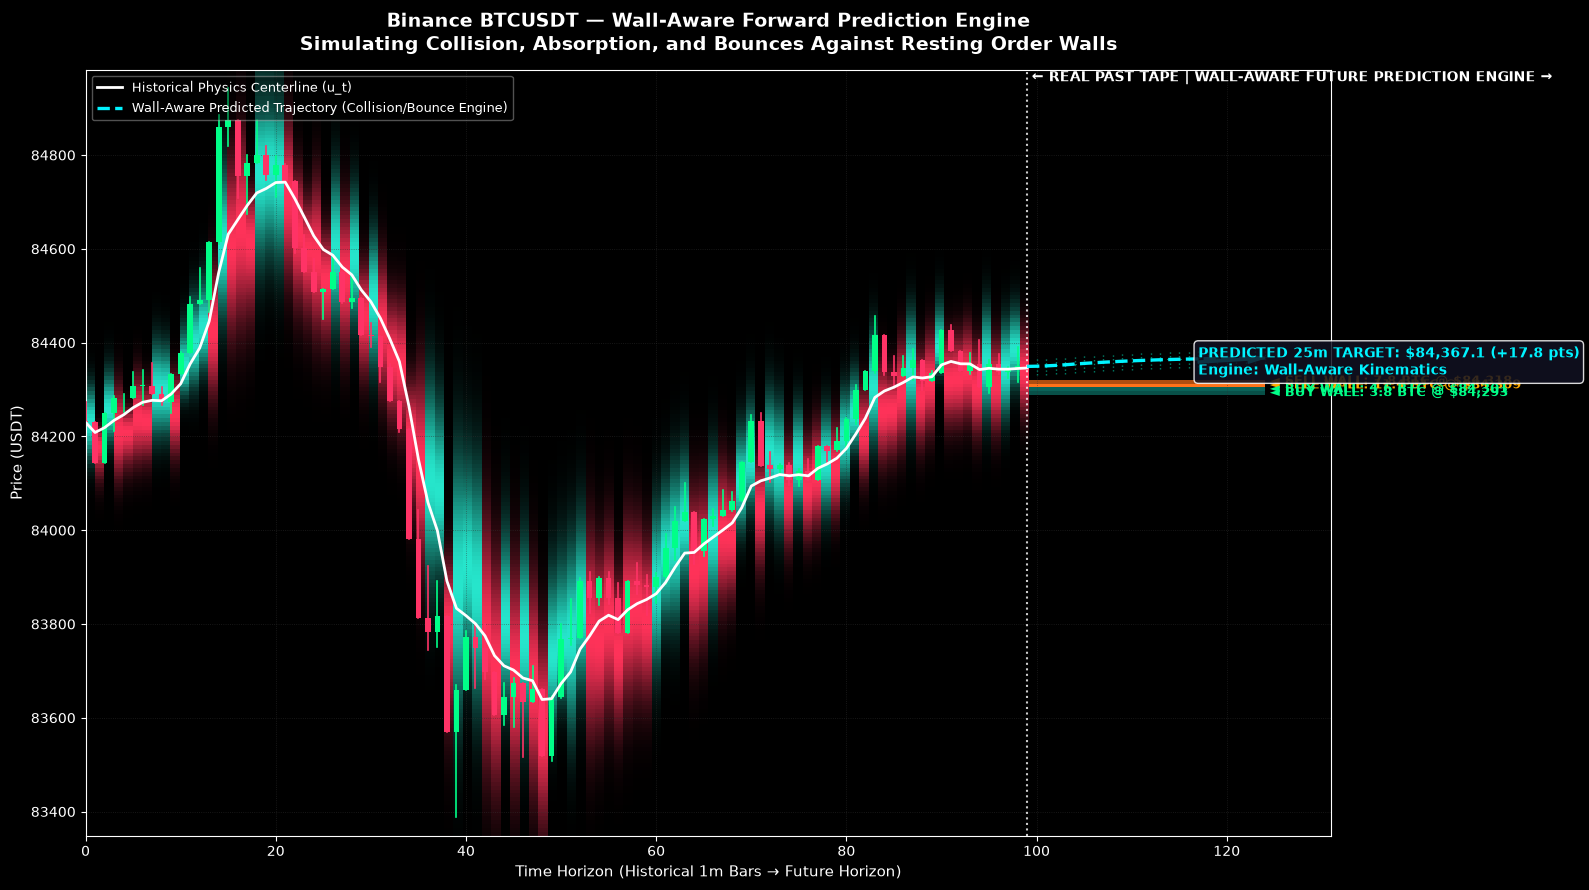

In [23]:
# ==============================================================================
# BTCUSDT WALL-AWARE FORWARD PREDICTION ENGINE & GHOST CANDLES
# Simulates Collision, Absorption, and Bounces Against Live Resting Order Walls
# ==============================================================================
%matplotlib inline
import urllib.request
import json
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# Accurate Standard Normal PDF & CDF in pure NumPy
def norm_pdf(x):
    return np.exp(-0.5 * x**2) / np.sqrt(2.0 * np.pi)

def norm_cdf(x):
    return 1.0 / (1.0 + np.exp(-1.702 * x))

# 1. Fetch Real-time 1m Klines & Live Resting L2 Depth
url_klines = "https://api.binance.com/api/v3/klines?symbol=BTCUSDT&interval=1m&limit=100"
req_k = urllib.request.Request(url_klines, headers={'User-Agent': 'Mozilla/5.0'})
raw_k = json.loads(urllib.request.urlopen(req_k, timeout=6).read().decode('utf-8'))

raw_depth = None
for depth_url in [
    "https://fapi.binance.com/fapi/v1/depth?symbol=BTCUSDT&limit=100",
    "https://api.binance.com/api/v3/depth?symbol=BTCUSDT&limit=100"
]:
    try:
        req_d = urllib.request.Request(depth_url, headers={'User-Agent': 'Mozilla/5.0'})
        raw_depth = json.loads(urllib.request.urlopen(req_d, timeout=5).read().decode('utf-8'))
        break
    except Exception:
        continue

times = [datetime.fromtimestamp(r[0] / 1000) for r in raw_k]
opens = np.array([float(r[1]) for r in raw_k])
highs = np.array([float(r[2]) for r in raw_k])
lows = np.array([float(r[3]) for r in raw_k])
closes = np.array([float(r[4]) for r in raw_k])
volumes = np.array([float(r[5]) for r in raw_k])
taker_buys = np.array([float(r[9]) for r in raw_k])
taker_sells = np.maximum(0.0, volumes - taker_buys)
n = len(closes)

book_bids = np.array([[float(p), float(q)] for p, q in raw_depth['bids']])
book_asks = np.array([[float(p), float(q)] for p, q in raw_depth['asks']])

# 2. Dynamic Volatility (ATR)
tr = np.zeros(n)
tr[0] = highs[0] - lows[0]
for i in range(1, n):
    tr[i] = max(highs[i] - lows[i], abs(highs[i] - closes[i - 1]), abs(lows[i] - closes[i - 1]))

alpha_atr = 2.0 / (14 + 1)
atr = np.zeros(n)
atr[0] = tr[0]
for i in range(1, n):
    atr[i] = alpha_atr * tr[i] + (1 - alpha_atr) * atr[i - 1]

# 3. Causal Decoupled Normalization (Buy/Sell Fuel)
decay = 0.08
mu_b, var_b = taker_buys[0], 1.0
mu_s, var_s = taker_sells[0], 1.0
norm_buy, norm_sell = np.zeros(n), np.zeros(n)

for i in range(n):
    db = taker_buys[i] - mu_b
    mu_b += decay * db
    var_b = (1 - decay) * var_b + decay * (db ** 2)
    norm_buy[i] = 100.0 / (1.0 + np.exp(-(taker_buys[i] - mu_b) / (np.sqrt(var_b) + 1e-6)))

    ds = taker_sells[i] - mu_s
    mu_s += decay * ds
    var_s = (1 - decay) * var_s + decay * (ds ** 2)
    norm_sell[i] = 100.0 / (1.0 + np.exp(-(taker_sells[i] - mu_s) / (np.sqrt(var_s) + 1e-6)))

# 4. Physics Kalman Wave
pos = closes[0]
vel = 0.0
wave_pos, wave_vel = np.zeros(n), np.zeros(n)

for i in range(n):
    net_force = (norm_buy[i] - norm_sell[i]) / 50.0
    u = 0.003 * net_force * atr[i]
    pos = pos + vel + 0.5 * u
    vel = 0.85 * vel + u
    pos = pos + 0.25 * (closes[i] - pos)
    wave_pos[i], wave_vel[i] = pos, vel

# 5. Future Projection Grid Setup
future_bars = 25
total_len = n + future_bars

min_p = min(np.min(lows), np.min(book_bids[:40, 0])) - 40
max_p = max(np.max(highs), np.max(book_asks[:40, 0])) + 40
p_grid = np.linspace(min_p, max_p, 200)
bin_size = (max_p - min_p) / len(p_grid)

# Map resting order books onto grid
wall_bids = np.zeros(len(p_grid))
wall_asks = np.zeros(len(p_grid))

for p, q in book_bids:
    idx = int((p - min_p) / bin_size)
    if 0 <= idx < len(p_grid): wall_bids[idx] += q

for p, q in book_asks:
    idx = int((p - min_p) / bin_size)
    if 0 <= idx < len(p_grid): wall_asks[idx] += q

max_wall = max(np.max(wall_bids), np.max(wall_asks), 1.0)
norm_bids = wall_bids / max_wall
norm_asks = wall_asks / max_wall

# 6. Combined Heatmap: Historical Skew Cloud + Future Resting Order Walls
heat_rgb = np.zeros((len(p_grid), total_len, 3))

for t in range(n):
    c_p = wave_pos[t]
    sigma = max(10.0, atr[t] * 1.3)
    v_norm = np.clip(wave_vel[t] / 15.0, -1.5, 1.5)
    f_net = (norm_buy[t] - norm_sell[t]) / 50.0
    skew_alpha = 2.5 * (f_net + 0.8 * v_norm)

    z = (p_grid - c_p) / sigma
    density = 2.0 * norm_pdf(z) * norm_cdf(skew_alpha * z)
    density = density / (np.max(density) + 1e-6)
    intensity = density ** 1.3

    if skew_alpha >= 0:
        heat_rgb[:, t, 0] = intensity * 0.15
        heat_rgb[:, t, 1] = intensity * 0.90
        heat_rgb[:, t, 2] = intensity * 0.80
    else:
        heat_rgb[:, t, 0] = intensity * 1.00
        heat_rgb[:, t, 1] = intensity * 0.20
        heat_rgb[:, t, 2] = intensity * 0.35

for t in range(n, total_len):
    heat_rgb[:, t, 0] = np.maximum(heat_rgb[:, t, 0], norm_asks * 1.0)
    heat_rgb[:, t, 1] = np.maximum(heat_rgb[:, t, 1], norm_asks * 0.45)
    heat_rgb[:, t, 2] = np.maximum(heat_rgb[:, t, 2], norm_asks * 0.10)

    heat_rgb[:, t, 0] = np.maximum(heat_rgb[:, t, 0], norm_bids * 0.10)
    heat_rgb[:, t, 1] = np.maximum(heat_rgb[:, t, 1], norm_bids * 0.95)
    heat_rgb[:, t, 2] = np.maximum(heat_rgb[:, t, 2], norm_bids * 0.85)

# ==============================================================================
# 7. WALL-AWARE PHYSICS FORWARD SIMULATION (Collision & Absorption Engine)
# ==============================================================================
sim_p = np.zeros(future_bars + 1)
sim_v = np.zeros(future_bars + 1)
sim_p[0] = closes[-1]
sim_v[0] = wave_vel[-1]

ghost_candles = []
cur_atr = atr[-1]

for step in range(future_bars):
    cp = sim_p[step]
    cv = sim_v[step]
    
    # 1. Sense nearby resting walls within 1.0 ATR distance
    idx_p = int((cp - min_p) / bin_size)
    sensor_range = int(cur_atr / bin_size)
    
    nearby_ask_depth = 0.0
    nearby_bid_depth = 0.0
    
    for offset in range(1, sensor_range + 1):
        if idx_p + offset < len(wall_asks):
            dist_weight = 1.0 - (offset / (sensor_range + 1))
            nearby_ask_depth += wall_asks[idx_p + offset] * dist_weight
            
    for offset in range(1, sensor_range + 1):
        if idx_p - offset >= 0:
            dist_weight = 1.0 - (offset / (sensor_range + 1))
            nearby_bid_depth += wall_bids[idx_p - offset] * dist_weight

    # 2. Physics Wall Impedance Force (Repulsion)
    wall_repulsion_force = (nearby_bid_depth - nearby_ask_depth) * 0.45
    
    # 3. Viscous Drag & Wall Interaction
    drag = 0.88
    next_v = (cv * drag) + wall_repulsion_force
    next_p = cp + next_v
    
    sim_v[step + 1] = next_v
    sim_p[step + 1] = next_p
    
    # Generate Synthetic Ghost Predicted Candle
    c_open = cp
    c_close = next_p
    wick_noise = cur_atr * 0.35
    c_high = max(c_open, c_close) + wick_noise
    c_low = min(c_open, c_close) - wick_noise
    ghost_candles.append((c_open, c_high, c_low, c_close))

# 8. Rendering
plt.style.use('dark_background')
fig, ax1 = plt.subplots(figsize=(16, 9))

extent = [0, total_len - 1, min_p, max_p]
ax1.imshow(heat_rgb, origin='lower', aspect='auto', extent=extent, zorder=1)

# Historical Candlesticks
for i in range(n):
    color = '#00ff88' if closes[i] >= opens[i] else '#ff3366'
    ax1.plot([i, i], [lows[i], highs[i]], color=color, lw=1.2, zorder=3)
    body_low = min(opens[i], closes[i])
    body_high = max(opens[i], closes[i])
    ax1.bar(i, max(1.5, body_high - body_low), bottom=body_low, color=color, width=0.6, zorder=4)

# Future Ghost Candles (Predicted Candle Progression)
for s, (g_o, g_h, g_l, g_c) in enumerate(ghost_candles):
    f_idx = n + s
    color = '#00ffcc' if g_c >= g_o else '#ff5588'
    ax1.plot([f_idx, f_idx], [g_l, g_h], color=color, lw=1.0, alpha=0.5, linestyle=':', zorder=3)
    b_low = min(g_o, g_c)
    b_high = max(g_o, g_c)
    ax1.bar(f_idx, max(1.5, b_high - b_low), bottom=b_low, color=color, width=0.55, alpha=0.45, zorder=4)

# Historical Physics Wave
ax1.plot(range(n), wave_pos, color='#ffffff', lw=2.0, label='Historical Physics Centerline (u_t)', zorder=5)

# Future Wall-Aware Trajectory Line
future_x = np.arange(n - 1, total_len)
ax1.plot(future_x, sim_p, '--', color='#00f3ff', lw=2.4, label='Wall-Aware Predicted Trajectory (Collision/Bounce Engine)', zorder=7)

# Dividing Vertical Line
ax1.axvline(n - 1, color='#ffffff', linestyle=':', lw=1.5, alpha=0.8, zorder=6)
ax1.text(n - 0.5, max_p - 25, "← REAL PAST TAPE | WALL-AWARE FUTURE PREDICTION ENGINE →", 
         color='#ffffff', fontsize=10, fontweight='bold', zorder=7)

# Annotate Top Limit Walls
top_ask_idx = np.argsort(wall_asks)[-3:]
for idx in top_ask_idx:
    if wall_asks[idx] > 1.5:
        p_val = p_grid[idx]
        ax1.text(total_len - 1, p_val, f" ◄ SELL WALL: {wall_asks[idx]:.1f} BTC @ ${p_val:,.0f}", 
                 color='#ffaa00', fontsize=9, fontweight='bold', va='center', zorder=8)

top_bid_idx = np.argsort(wall_bids)[-3:]
for idx in top_bid_idx:
    if wall_bids[idx] > 1.5:
        p_val = p_grid[idx]
        ax1.text(total_len - 1, p_val, f" ◄ BUY WALL: {wall_bids[idx]:.1f} BTC @ ${p_val:,.0f}", 
                 color='#00ff88', fontsize=9, fontweight='bold', va='center', zorder=8)

# Interaction Callout on Final Projected Candle
end_p = sim_p[-1]
net_drift = end_p - closes[-1]
interaction_label = f"PREDICTED 25m TARGET: ${end_p:,.1f} ({net_drift:+.1f} pts)\nEngine: Wall-Aware Kinematics"
ax1.annotate(interaction_label, xy=(total_len - 1, end_p), xytext=(total_len - 8, end_p + (25 if net_drift < 0 else -35)),
             arrowprops=dict(facecolor='#00f3ff', edgecolor='#00f3ff', width=1.5, headwidth=6),
             color='#00f3ff', fontsize=10, fontweight='bold', bbox=dict(boxstyle='round,pad=0.3', facecolor='#111122', alpha=0.85), zorder=9)

ax1.set_ylim(min_p, max_p)
ax1.set_xlim(0, total_len + 6)
ax1.set_title(f"Binance BTCUSDT — Wall-Aware Forward Prediction Engine\nSimulating Collision, Absorption, and Bounces Against Resting Order Walls", fontsize=14, fontweight='bold', pad=14)
ax1.set_ylabel("Price (USDT)", fontsize=11)
ax1.set_xlabel("Time Horizon (Historical 1m Bars → Future Horizon)", fontsize=11)
ax1.legend(loc='upper left', framealpha=0.4, fontsize=9)
ax1.grid(color='#333333', linestyle=':', lw=0.6, alpha=0.6)

plt.tight_layout()
plt.show()